# DR – Druhá semestrální práce

## Zadání

1. Získejte datovou sadu průměrných denních teplot v Plzni za období od 1. ledna 1970 do 12. prosince 2025.

2. Rozdělte datovou sadu podle jednotlivých kalendářních roků.

3. Vykreslete graf průměrných ročních teplot. V samostatném grafu zobrazte průběh denních teplot v jednotlivých letech.

4. Pomocí **nepárového t-testu** zjistěte, které roky se statisticky významně liší od celkového průměru ročních teplot. Určete, které roky jsou statisticky významně chladnější a které teplejší než tento průměr. Použijte hladinu významnosti 0.01.

5. Pomocí **párového t-testu** zjistěte, které roky se statisticky významně liší od celkového průměru ročních teplot. Určete, které roky jsou statisticky významně chladnější a které teplejší než tento průměr. Použijte hladinu významnosti 0.01.

6. Vykreslete histogram odchylek a posuďte, zda jsou splněny předpoklady pro použití t-testu.

7. Použijte vhodný **párový neparametrický** test a vyhodnoťte, které roky se statisticky významně liší od celkového průměru ročních teplot. Určete, které roky jsou statisticky významně chladnější a které teplejší než tento průměr. Použijte hladinu významnosti 0.01.

8. Porovnejte výsledky nepárového a párového t-testu. Vyhodnoťte, zda se statisticky významně odlišuje více, nebo méně roků při použití nepárového či párového testu. Stejně tak porovnejte výsledky párového t-testu a zvoleného párového neparametrického testu. Pokuste se vysvětlit případné rozdíly ve výsledcích.

9. Vyhodnoťte trend průměrných ročních teplot a otestujte hypotézu, že tento trend je statisticky významně odlišný od nuly.

## Dodatečné informace z emailu
Zadání opět vypacujte ve formě ipython notebooku a zašlete mi ho.

Jako úkol nad rámec zadání si můžete širokou paletu možnosti od srovnání s jinými místy planety až po analýzu, které dny v roce se více hodí pro porovnávání teplot. V zadání je také schválně ponechána jedna (a neúmyslně možná více) nepřesnost/nevhodnost. Její ohalení a náprava také může být úkolem nad rámec zadání.

Varování: pozor na příliš časté používání API zvolené služby. Nezapomínejte vyčkat několik sekund před opakováním dotazu.

## Vypracování

### 1. Získání datavé sady

Souřadnice Plzně jsou 49° 44′ 51″ N, 13° 22′ 39″ E (zdroj: https://en.wikipedia.org/wiki/Plze%C5%88).

Následuje definice parametrů datasetu:

In [144]:
# --------------------------------------------------
# Configuration
# --------------------------------------------------

location = {
    "name": "Pilsen",
    "continent": "Europe",
    "timezone": "Europe/Prague",
    "latitude": (49, 44, 51),
    "longitude": (13, 22, 39),
}

start_date = "1970-01-01"
# end_date = "2025-12-31"
end_date = "2025-12-12" # zadani rika 12. prosince, ale tady bylo napsano 31. prosince
# Preklep, nebo kontrola toho ze jsem cetl zadani?
# nebo kontrola toho ze to byla hozeny cely do LLMka?
# who knows

# --------------------------------------------------
# Derived parameters
# --------------------------------------------------

for key in ("latitude", "longitude"):
    degrees, minutes, seconds = location[key]
    location[key] = degrees + minutes / 60 + seconds / 3600

# --------------------------------------------------
# Output
# --------------------------------------------------

print(f"Location: {location['name']}")
print(f"Continent: {location['continent']}")
print(f"Timezone: {location['timezone']}")
print(f"Latitude: {location['latitude']:.3f}")
print(f"Longitude: {location['longitude']:.3f}")
print(f"Start date: {start_date}")
print(f"End date: {end_date}")

Location: Pilsen
Continent: Europe
Timezone: Europe/Prague
Latitude: 49.748
Longitude: 13.378
Start date: 1970-01-01
End date: 2025-12-12


Následuje výpočet, kolik bodů pozorování bychom měli dostat.

In [106]:
import datetime

date_start = datetime.date.fromisoformat(start_date)
date_end = datetime.date.fromisoformat(end_date)

n_days_expected = (date_end - date_start).days + 1

print(f"Start date: {date_start}")
print(f"End date: {date_end}")
print(f"Expected number of observations: {n_days_expected:,}")

Start date: 1970-01-01
End date: 2025-12-12
Expected number of observations: 20,435


K získání dat byla použita otavřená data s url adresou v následujícím kódu. Tento kód provádí záskání dat a kontrolu jejich správnosti.

In [ ]:
import requests
import pandas as pd
import json

# --------------------------------------------------
# Open-Meteo API
# --------------------------------------------------

url = "https://archive-api.open-meteo.com/v1/archive"

daily_variables = [
    "temperature_2m_mean",
    "temperature_2m_min",
    "temperature_2m_max",
]

params = {
    "latitude": location["latitude"],
    "longitude": location["longitude"],
    "start_date": start_date,
    "end_date": end_date,
    "daily": daily_variables,
    "timezone": location["timezone"],
    "models": "era5",
}

# --------------------------------------------------
# Download data
# --------------------------------------------------

# Pro prevenci příliš častého volání api jsem po prvním spuštění data uložil do souboru data.json
# with requests.Session() as session:
#     response = session.get(url, params=params, timeout=(10, 120))
#     response.raise_for_status()
#     result = response.json()

# json_str = json.dumps(result, indent=2)
# with open("data_Pilsen.json", "w") as f:
#     f.write(json_str)


with open("data_Pilsen.json") as f:
    result = json.load(f)



# --------------------------------------------------
# Extract data
# --------------------------------------------------

if "daily" not in result:
    raise ValueError("Daily data are missing from the API response.")

daily = result["daily"]

df = pd.DataFrame({
    "date": pd.to_datetime(daily["time"]),
    "temperature_mean": daily["temperature_2m_mean"],
    "temperature_min": daily["temperature_2m_min"],
    "temperature_max": daily["temperature_2m_max"],
})

# --------------------------------------------------
# Data validation
# --------------------------------------------------

print(f"Obtained observations: {len(df):,}")
print(f"Expected observations: {n_days_expected:,}")

if len(df) != n_days_expected:
    print("WARNING: Unexpected number of observations!")

if df["date"].duplicated().any():
    raise ValueError("Duplicate dates detected.")

if not df["date"].is_monotonic_increasing:
    raise ValueError("Dates are not in chronological order.")

missing = df.isna().sum()

if missing.any():
    print("\nMissing values:")
    print(missing[missing > 0])

# --------------------------------------------------
# API metadata
# --------------------------------------------------

print("\nTemperature units:")
print(result.get("daily_units", {}))

print(f"\nTimezone: {result.get('timezone')}")
print(f"Elevation: {result.get('elevation')} m")

df.head()

Obtained observations: 20,435
Expected observations: 20,435

Temperature units:
{'time': 'iso8601', 'temperature_2m_mean': '°C', 'temperature_2m_min': '°C', 'temperature_2m_max': '°C'}

Timezone: Europe/Prague
Elevation: 319.0 m


,date,temperature_mean,temperature_min,temperature_max
0,1970-01-01,-4.6,-5.6,-3.8
1,1970-01-02,-4.9,-6.3,-2.7
2,1970-01-03,-0.5,-2.7,1.1
3,1970-01-04,0.4,-2.3,1.9
4,1970-01-05,-2.0,-4.2,1.8


Následující kód vykreslí všechny body datové sady.

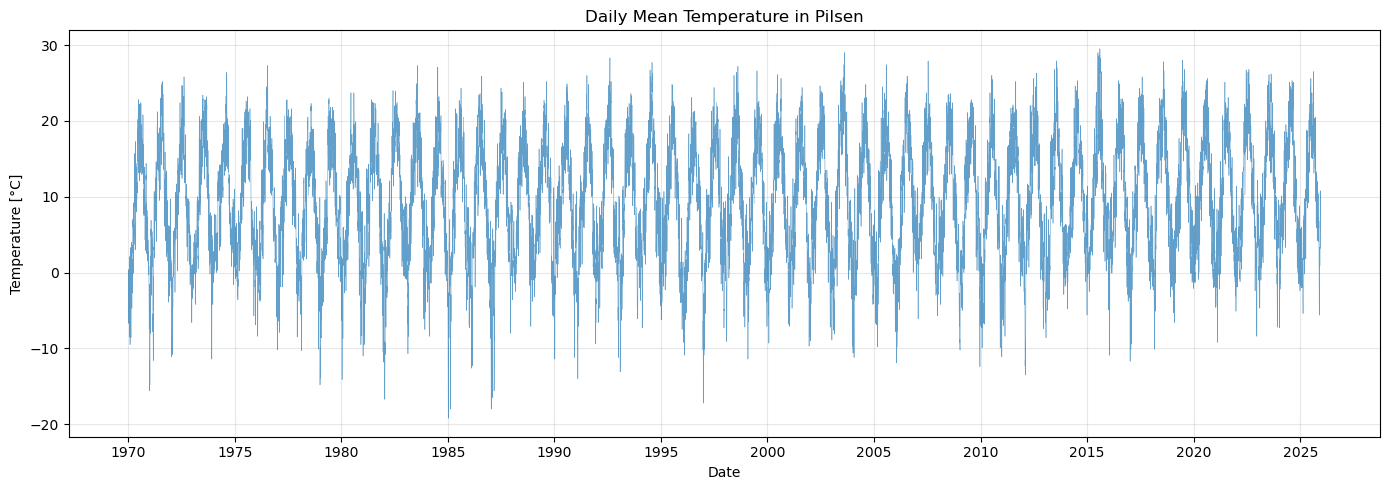

In [108]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --------------------------------------------------
# Plot daily temperature
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df["date"],
    df["temperature_mean"],
    linewidth=0.4,
    alpha=0.7,
)

ax.set_title(f"Daily Mean Temperature in {location['name']}")
ax.set_ylabel("Temperature [°C]")
ax.set_xlabel("Date")

# Date formatting
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

### 2. Rozdělení datové sady

In [109]:
# --------------------------------------------------
# Split data into annual DataFrames
# --------------------------------------------------

df["year"] = df["date"].dt.year

df_annual = {
    year: group.drop(columns="year").reset_index(drop=True)
    for year, group in df.groupby("year")
}

print(f"Number of years: {len(df_annual)}")
print(f"Available years: {list(df_annual.keys())}")

df_annual[2025]

Number of years: 56
Available years: [1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


,date,temperature_mean,temperature_min,temperature_max
0,2025-01-01,2.6,-0.8,6.1
1,2025-01-02,4.4,0.0,8.0
2,2025-01-03,0.5,-0.4,1.9
3,2025-01-04,-0.8,-3.7,0.5
4,2025-01-05,-0.0,-4.3,5.5
...,...,...,...,...
341,2025-12-08,10.2,6.9,12.5
342,2025-12-09,10.8,8.8,12.8
343,2025-12-10,8.1,6.2,10.1
344,2025-12-11,7.5,3.0,10.2


### 3. Vykreslení průběhů teplot

Následují kód vykresluje vývoj průměrné roční teploty.

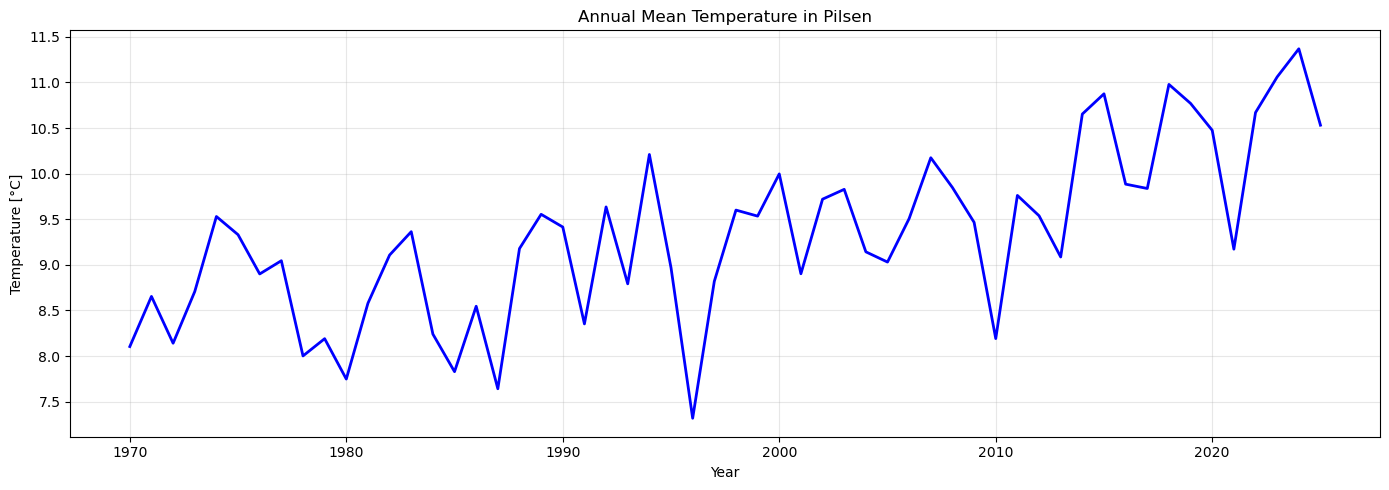

In [110]:
# --------------------------------------------------
# Annual temperature statistics
# --------------------------------------------------

df_annual_stats = pd.DataFrame({
    year: {
        "mean": data["temperature_mean"].mean(),
    }
    for year, data in df_annual.items()
}).T
df_annual_stats.index.name = "year"

# --------------------------------------------------
# Plot annual mean temperature ± standard deviation
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 5))
years = df_annual_stats.index
means = df_annual_stats["mean"]
ax.plot(years, means, color="blue", linewidth=2.0)
ax.set_title(f"Annual Mean Temperature in {location['name']}")
ax.set_xlabel("Year")
ax.set_ylabel("Temperature [°C]")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Následující kód vykresluje průběh teplot během roku a průměrný rok.

**Pozor rok 2025 není úplný!**
- dojde k mírnému zkreslení výsledků
- (viz úkoly nad rámec zadání)

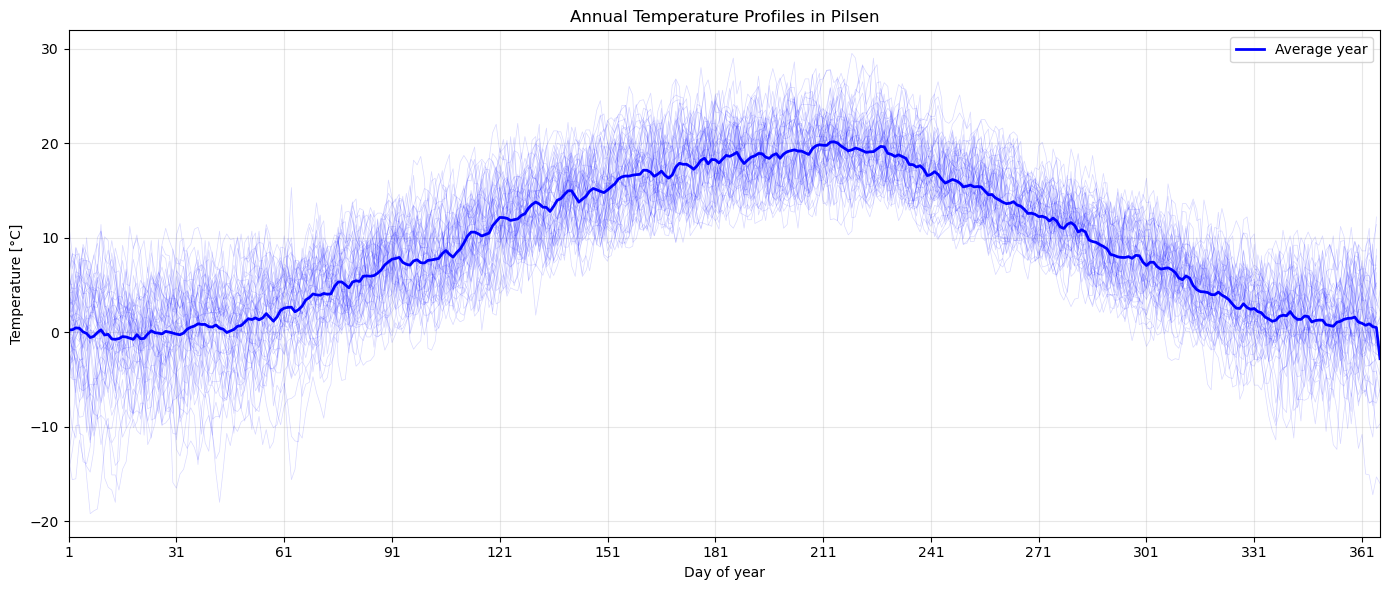

In [111]:
# --------------------------------------------------
# Average annual temperature profile
# --------------------------------------------------

df["day_of_year"] = df["date"].dt.day_of_year

df_average_year = (
    df.groupby("day_of_year")["temperature_mean"]
    .agg(["mean", "std"])
    .reset_index()
)

df_average_year.head()

# --------------------------------------------------
# Plot temperature profiles for all years
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

for year, data in df_annual.items():
    ax.plot(
        data["date"].dt.day_of_year,
        data["temperature_mean"],
        color="blue",
        linewidth=0.5,
        alpha=0.15,
    )

# Average annual profile
ax.plot(
    df_average_year["day_of_year"],
    df_average_year["mean"],
    linewidth=2.0,
    color="blue",
    label="Average year",
)

ax.set_title(f"Annual Temperature Profiles in {location['name']}")
ax.set_xlabel("Day of year")
ax.set_ylabel("Temperature [°C]")

ax.set_xlim(1, 366)
ax.set_xticks(range(1, 367, 30))

ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

# Zadání (abych nemusel scrollovat nahoru a dolů)
4. Pomocí **nepárového t-testu** zjistěte, které roky se statisticky významně liší od celkového průměru ročních teplot. Určete, které roky jsou statisticky významně chladnější a které teplejší než tento průměr. Použijte hladinu významnosti 0.01.

5. Pomocí **párového t-testu** zjistěte, které roky se statisticky významně liší od celkového průměru ročních teplot. Určete, které roky jsou statisticky významně chladnější a které teplejší než tento průměr. Použijte hladinu významnosti 0.01.

6. Vykreslete histogram odchylek a posuďte, zda jsou splněny předpoklady pro použití t-testu.

7. Použijte vhodný **párový neparametrický** test a vyhodnoťte, které roky se statisticky významně liší od celkového průměru ročních teplot. Určete, které roky jsou statisticky významně chladnější a které teplejší než tento průměr. Použijte hladinu významnosti 0.01.

8. Porovnejte výsledky nepárového a párového t-testu. Vyhodnoťte, zda se statisticky významně odlišuje více, nebo méně roků při použití nepárového či párového testu. Stejně tak porovnejte výsledky párového t-testu a zvoleného párového neparametrického testu. Pokuste se vysvětlit případné rozdíly ve výsledcích.

9. Vyhodnoťte trend průměrných ročních teplot a otestujte hypotézu, že tento trend je statisticky významně odlišný od nuly.

### 4. Použití nepárových testů


**Pozor rok 2025 není úplný!**
- dojde k mírnému zkreslení výsledků
- (viz úkoly nad rámec zadání)

Obecná formulace hypotéz:

* H0: odchylka od průměru je způsobena náhodnými poruchami.
* H1: odchyla od průměru je způsobena tím, že datová sada má jiný/nižší/vyšší průměr.

Konkrétní formulace při použití nepárového t-testu:

\begin{align}
H_0:& \mu_\text{rok} = \mu_\text{avg},\\
H_1 (\text{rok je jiný}):& \mu_\text{rok} \ne \mu_\text{avg},\\
H_1 (\text{rok je chladnější}):& \mu_\text{rok} < \mu_\text{avg},,\\
H_1(\text{rok je teplejší}):& \mu_\text{rok} > \mu_\text{avg},\\
\end{align}

In [112]:
tests_results = {}

In [113]:
from scipy.stats import ttest_ind

test_name = "t-test"
test_type = "independent"

tests_results[test_name] = {
        test_type: {
            "two-sided": {},
            "less": {},
            "greater": {},
        },
}

average_year = df_average_year["mean"]

# df_annual obsahuje data temp_mean, temp_min, temp_max a dny a je to groupnute podle roku
for year, data in df_annual.items():

    actual_year = data["temperature_mean"] # vsechny data v roce

    p_value_two_sided = ttest_ind(actual_year,
                                   average_year,
                                   equal_var=False,
                                   alternative="two-sided").pvalue
    p_value_less = ttest_ind(actual_year,
                             average_year,
                             equal_var=False,
                             alternative="less").pvalue
    p_value_greater = ttest_ind(actual_year,
                                 average_year,
                                 equal_var=False,
                                 alternative="greater").pvalue  

    tests_results[test_name][test_type]["two-sided"][year] = p_value_two_sided
    tests_results[test_name][test_type]["less"][year] = p_value_less
    tests_results[test_name][test_type]["greater"][year] = p_value_greater

Vykreslení průběhu p-hodnot pro jednotlivé roky.

Hladina významnosti alpha = 0.01
Významně odlišné roky (two-sided) [9]: [1980, 1987, 1996, 2014, 2015, 2018, 2019, 2023, 2024]
Významně chladnější roky (less)   [5]: [1978, 1980, 1985, 1987, 1996]
Významně teplejší roky (greater)  [8]: [2014, 2015, 2018, 2019, 2022, 2023, 2024, 2025]


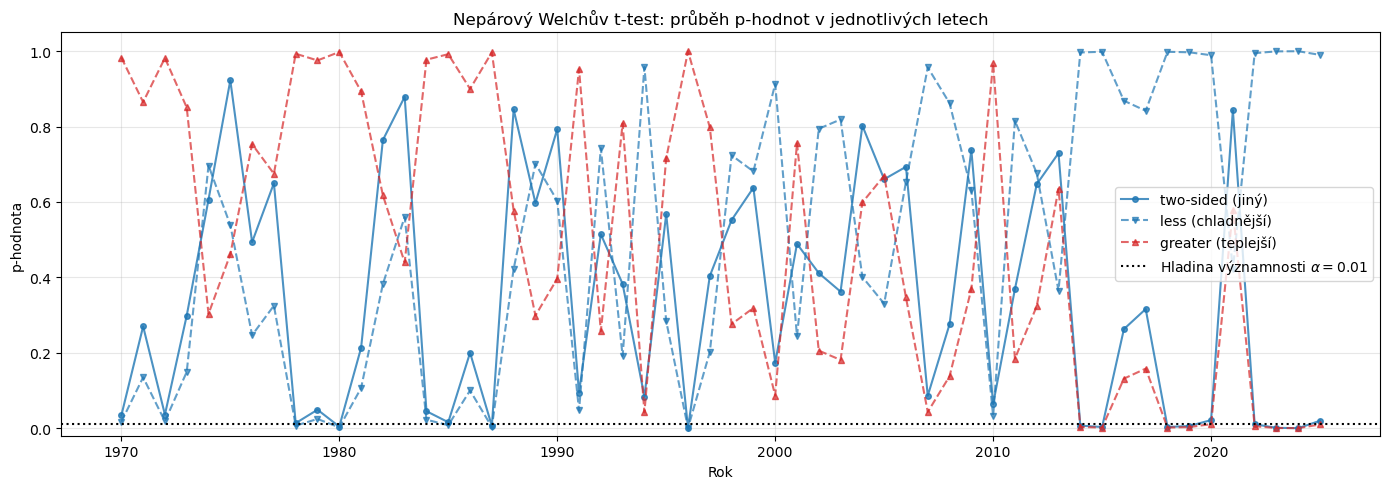

In [114]:
def plot_test_results(results, alpha=0.01, title="Grafické zobrazení p-hodnot"):

    years_list = list(results["two-sided"].keys())
    p_two = list(results["two-sided"].values())
    p_less = list(results["less"].values())
    p_greater = list(results["greater"].values())

    # Výpis statisticky významných let na hladině alpha = 0.01
    sig_different = [y for y, p in results["two-sided"].items() if p < alpha]
    sig_colder = [y for y, p in results["less"].items() if p < alpha]
    sig_warmer = [y for y, p in results["greater"].items() if p < alpha]

    print(f"Hladina významnosti alpha = {alpha}")
    print(f"Významně odlišné roky (two-sided) [{len(sig_different)}]: {sig_different}")
    print(f"Významně chladnější roky (less)   [{len(sig_colder)}]: {sig_colder}")
    print(f"Významně teplejší roky (greater)  [{len(sig_warmer)}]: {sig_warmer}")

    # Vykreslení průběhu p-hodnot
    fig, ax = plt.subplots(figsize=(14, 5))

    ax.set_title(title);
    ax.plot(years_list, p_two, marker="o", markersize=4, linestyle="-", alpha=0.8, label="two-sided (jiný)")
    ax.plot(years_list, p_less, marker="v", markersize=4, linestyle="--", alpha=0.7, color="tab:blue", label="less (chladnější)")
    ax.plot(years_list, p_greater, marker="^", markersize=4, linestyle="--", alpha=0.7, color="tab:red", label="greater (teplejší)")

    ax.axhline(y=alpha, color="black", linestyle=":", linewidth=1.5, label=f"Hladina významnosti $\\alpha = {alpha}$")

    ax.set_xlabel("Rok")
    ax.set_ylabel("p-hodnota")
    ax.set_ylim(-0.02, 1.05)
    ax.grid(True, alpha=0.3)
    ax.legend()

    fig.tight_layout()
    plt.show()


    # ax.set_title("")
results = tests_results["t-test"]["independent"]
plot_test_results(results, title="Nepárový Welchův t-test: průběh p-hodnot v jednotlivých letech")

### Rok 2025 (bude relevatntní později)

In [115]:
print(tests_results["t-test"]["independent"]["two-sided"][2025])

print(tests_results["t-test"]["independent"]["greater"][2025])

print(tests_results["t-test"]["independent"]["less"][2025])

0.01971223480257376
0.00985611740128688
0.9901438825987131


In [116]:
print(tests_results["t-test"]["independent"]["two-sided"][2022])

print(tests_results["t-test"]["independent"]["greater"][2022])

0.010356499505154458
0.005178249752577229


Zajímavá skutečnost: 
- pro roky zamítáme $H_0$ 2022, 2023 i 2024 ve prospěch $H_1(\text{rok je teplejší}): \mu_\text{rok} > \mu_\text{avg}$
- pro roky 2023, 2024 zamítáme $H_0$ ve prospěch $H_1 (\text{rok je jiný}): \mu_\text{rok} \ne \mu_\text{avg}$, ale to se nestane pro rok 2022
- proč se tomu tak děje?
- oboustranný test dělí hladinu významnosti na dvě poloviny 
- p-hodnota u oboustraného testu je poté dvojnásobkem p-hodnoty jednostranného testu 
- u roku 2022 vyšla jednostranná p-hodnota mezi $0.005$ a $0.01$, což stačí na zamítnutí $H_0$, ale po vynásobení dvěma přeskočila hrancii $\alpha$ pro oboustranný test


### 5. Použití párových testů

Obecná formulace hypotéz:

* H0: odchylka od průměru je způsobena náhodnými poruchami.
* H1: odchyla od průměru je způsobena tím, že datová sada má jiný/nižší/vyšší průměr.

Konkrétní formulace při použití párového t-testu:

\begin{align}
H_0:& \mu_\text{rok} = \mu_\text{avg},\\
H_1 (\text{rok je jiný}):& \mu_\text{rok} \ne \mu_\text{avg},\\
H_1 (\text{rok je chladnější}):& \mu_\text{rok} < \mu_\text{avg},,\\
H_1(\text{rok je teplejší}):& \mu_\text{rok} > \mu_\text{avg},\\
\end{align}

In [117]:
from scipy.stats import ttest_rel

test_name = "t-test"
test_type = "paired"

# Tady byla chybka pri prepisovani puvodnich dat
tests_results[test_name][test_type] = {
            "two-sided": {},
            "less": {},
            "greater": {},
}




average_year_with_days = df_average_year[["mean","day_of_year"]]
print(len(average_year_with_days))
# prumerny rok obsahuje data i z 29. unora, coz je pouze pro prestupni roky

for year, data in df_annual.items():
    # Musim mergenout podle datumu!
    actual_year_df = pd.DataFrame({
        "day_of_year": data["date"].dt.day_of_year,
        "temperature": data["temperature_mean"]
    })

    # data nejdrive mergnu, abych zajistil ze se v kazdem roce porovnavaji spravne dny
    merged = pd.merge(
        actual_year_df,
        average_year_with_days,
        on="day_of_year",
        how="left",
    )

    actual_year_data = merged["temperature"]
    average_year_data = merged["mean"]


    p_value_two_sided = ttest_rel(actual_year_data, average_year_data, alternative="two-sided").pvalue
    p_value_less = ttest_rel(actual_year_data, average_year_data, alternative="less").pvalue
    p_value_greater = ttest_rel(actual_year_data, average_year_data, alternative="greater").pvalue

    tests_results[test_name][test_type]["two-sided"][year] = p_value_two_sided
    tests_results[test_name][test_type]["less"][year] = p_value_less
    tests_results[test_name][test_type]["greater"][year] = p_value_greater

366


Vykreslení průběhu p-hodnot pro jednotlivé roky.

Hladina významnosti alpha = 0.01
Významně odlišné roky (two-sided) [30]: [1970, 1971, 1972, 1973, 1978, 1979, 1980, 1981, 1984, 1985, 1986, 1987, 1991, 1994, 1996, 2000, 2007, 2008, 2010, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2022, 2023, 2024, 2025]
Významně chladnější roky (less)   [18]: [1970, 1971, 1972, 1973, 1978, 1979, 1980, 1981, 1984, 1985, 1986, 1987, 1991, 1993, 1996, 1997, 2001, 2010]
Významně teplejší roky (greater)  [17]: [1994, 2000, 2003, 2007, 2008, 2011, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2022, 2023, 2024, 2025]


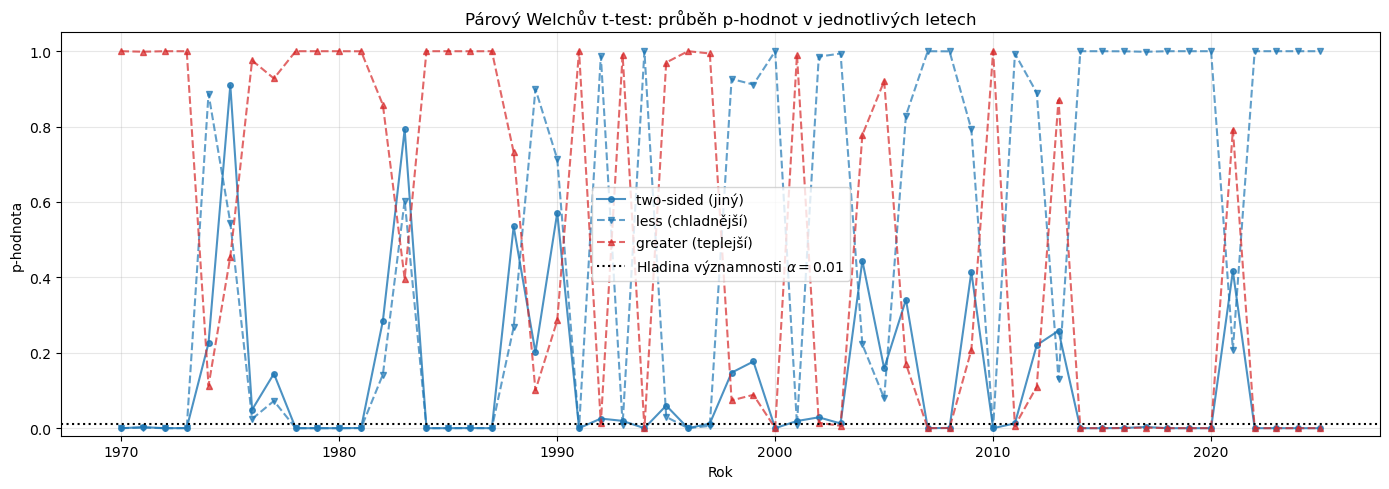

In [118]:
results = tests_results["t-test"]["paired"]
plot_test_results(results, title="Párový Welchův t-test: průběh p-hodnot v jednotlivých letech")

### Párový ttest je statisticky "silnější", protože rozptyl dat,se kterými počítáme, je mnohem menší

### 6. Analýza histogramu odchylek

Následující kód vykreslí histogram odchylek a zakreslí průběh normálního rozdělení se střední hodnotou a rozptylem odpovídající střední hodnotě a rozptylu odchylek.

In [119]:
# Predpoklady ttestu
    # histogram odchylek by mel odpovida normalnimu rozdeleni
    # nezavislost pozorovani

df

,date,temperature_mean,temperature_min,temperature_max,year,day_of_year
0,1970-01-01,-4.6,-5.6,-3.8,1970,1
1,1970-01-02,-4.9,-6.3,-2.7,1970,2
2,1970-01-03,-0.5,-2.7,1.1,1970,3
3,1970-01-04,0.4,-2.3,1.9,1970,4
4,1970-01-05,-2.0,-4.2,1.8,1970,5
...,...,...,...,...,...,...
20430,2025-12-08,10.2,6.9,12.5,2025,342
20431,2025-12-09,10.8,8.8,12.8,2025,343
20432,2025-12-10,8.1,6.2,10.1,2025,344
20433,2025-12-11,7.5,3.0,10.2,2025,345


In [120]:
df_average_year

,day_of_year,mean,std
0,1,0.253571,5.182136
1,2,0.250000,4.847305
2,3,0.460714,5.144765
3,4,0.416071,5.116241
4,5,0.039286,5.418141
...,...,...,...
361,362,0.732727,4.452426
362,363,0.883636,4.967329
363,364,0.592727,5.105257
364,365,0.494545,5.042355


In [121]:
merged_df_for_deviation = pd.merge(
    df,
    df_average_year,
    on="day_of_year",
    how="left"
   )
merged_df_for_deviation
# Pozor! std asi neni to co chci?

,date,temperature_mean,temperature_min,temperature_max,year,day_of_year,mean,std
0,1970-01-01,-4.6,-5.6,-3.8,1970,1,0.253571,5.182136
1,1970-01-02,-4.9,-6.3,-2.7,1970,2,0.250000,4.847305
2,1970-01-03,-0.5,-2.7,1.1,1970,3,0.460714,5.144765
3,1970-01-04,0.4,-2.3,1.9,1970,4,0.416071,5.116241
4,1970-01-05,-2.0,-4.2,1.8,1970,5,0.039286,5.418141
...,...,...,...,...,...,...,...,...
20430,2025-12-08,10.2,6.9,12.5,2025,342,1.653571,4.416291
20431,2025-12-09,10.8,8.8,12.8,2025,343,1.358929,4.379239
20432,2025-12-10,8.1,6.2,10.1,2025,344,1.355357,4.068992
20433,2025-12-11,7.5,3.0,10.2,2025,345,1.708929,3.644985


In [122]:
deviation = merged_df_for_deviation["temperature_mean"] - merged_df_for_deviation["mean"]
print(deviation)
# odchylky uz mas => staci vykreslit histogram => todo histogram

0       -4.853571
1       -5.150000
2       -0.960714
3       -0.016071
4       -2.039286
           ...   
20430    8.546429
20431    9.441071
20432    6.744643
20433    5.791071
20434    1.550000
Length: 20435, dtype: float64


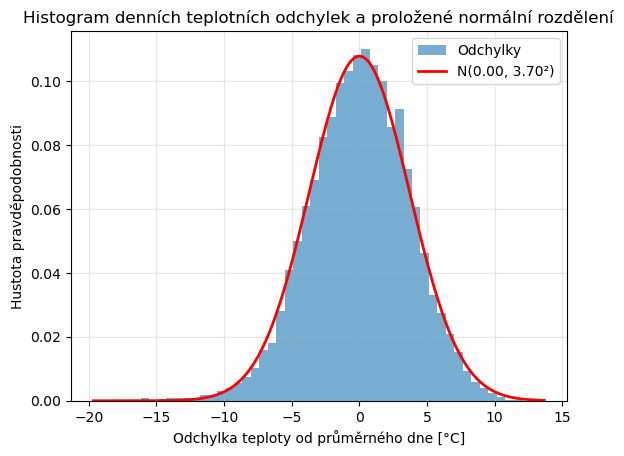

In [123]:
import numpy as np
from scipy.stats import norm

mean_dev = np.mean(deviation)
std_dev = np.std(deviation)
x = np.linspace(deviation.min()-1, deviation.max()+1, 200)
pdf = norm.pdf(x, mean_dev, std_dev)    

plt.figure()
plt.hist(deviation, bins=50, density=True, alpha=0.6, label="Odchylky")
plt.plot(x, pdf, "r-", lw=2, label=f"N({mean_dev:.2f}, {std_dev:.2f}²)")
plt.title("Histogram denních teplotních odchylek a proložené normální rozdělení")
plt.xlabel("Odchylka teploty od průměrného dne [°C]")
plt.ylabel("Hustota pravděpodobnosti")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



Porovnáním histogramu odchylek a odpovídajícího normálního rozdělení vidíme, že tvar Gaussovy křivky věrně kopíruje rozdělení odchylek. Je vidět mírné levostranné zašikmení.

K T-testu je ještě nutné podotknout, že předpokládá nezávislost jednotlivých pozorování. To u denních teplot ovšem není zaručeno. Teploty po sobě jdoucích dnech jsou korelované.

Přestože histogram odchylek odpovídá normálnímu rozdělení (a tím se splňuje jeden předpoklad T-testu), druhý předpoklad není zcela splněn, což může vést k nadhodnocení statistické významnosti. (Tz. test je moc sebevědomý, příliš snadno a často zamítá $H_0$ i když by neměl).

### 7. Použití neparametrického párového testu

**Wilconxonův test:**
- ptá se: "Jsou kladné a záporné odchylky rozložené symetricky kolem nuly?" 
- tj. je medián rozdílů == 0?

- předepsané buňky mluví o průměru, LLM mi řeklo, že se počítá s mediánem (resp. s rozdělením odchylek kolem nuly)?


Obecná formulace hypotéz:

* H0: odchylka od průměru je způsobena náhodnými poruchami.
* H1: odchyla od průměru je způsobena tím, že datová sada má jiný/nižší/vyšší průměr.

Konkrétní formulace při použití vybraného neparametrického testu:

\begin{align}
H_0:&\ \text{median}(d)=0,\\
H_1 (\text{rok je jiný}):& \text{median}(d)\ne 0,\\
H_1 (\text{rok je chladnější}):&\text{median}(d)<0 ,\\
H_1(\text{rok je teplejší}):&\text{median}(d)>0 ,\\
\end{align}

In [124]:
from scipy.stats import wilcoxon

test_name = "wilcoxon"
test_type = "paired"

tests_results[test_name] = {
    test_type: {
        "two-sided": {},
        "less": {},
        "greater": {}
        }
}


average_year_with_days = df_average_year[["mean","day_of_year"]]
print(len(average_year_with_days))
# prumerny rok obsahuje data i z 29. unora, coz je pouze pro prestupni roky

for year, data in df_annual.items():
    # Musim mergenout podle datumu!
    actual_year_df = pd.DataFrame({
        "day_of_year": data["date"].dt.day_of_year,
        "temperature": data["temperature_mean"]
    })

    # data nejdrive mergnu, abych zajistil ze se v kazdem roce porovnavaji spravne dny
    merged = pd.merge(
        actual_year_df,
        average_year_with_days,
        on="day_of_year",
        how="left",
    )

    actual_year_data = merged["temperature"]
    average_year_data = merged["mean"]


    p_value_two_sided = wilcoxon(actual_year_data, average_year_data, alternative="two-sided").pvalue
    p_value_less = wilcoxon(actual_year_data, average_year_data, alternative="less").pvalue
    p_value_greater = wilcoxon(actual_year_data, average_year_data, alternative="greater").pvalue

    tests_results[test_name][test_type]["two-sided"][year] = p_value_two_sided
    tests_results[test_name][test_type]["less"][year] = p_value_less
    tests_results[test_name][test_type]["greater"][year] = p_value_greater

366


Vykreslení průběhu p-hodnot pro jednotlivé roky.

Hladina významnosti alpha = 0.01
Významně odlišné roky (two-sided) [31]: [1970, 1972, 1973, 1978, 1979, 1980, 1981, 1984, 1985, 1986, 1987, 1991, 1994, 1996, 2000, 2003, 2007, 2008, 2010, 2011, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2022, 2023, 2024, 2025]
Významně chladnější roky (less)   [15]: [1970, 1972, 1973, 1978, 1979, 1980, 1981, 1984, 1985, 1986, 1987, 1991, 1996, 1997, 2010]
Významně teplejší roky (greater)  [18]: [1994, 2000, 2003, 2007, 2008, 2011, 2012, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2022, 2023, 2024, 2025]


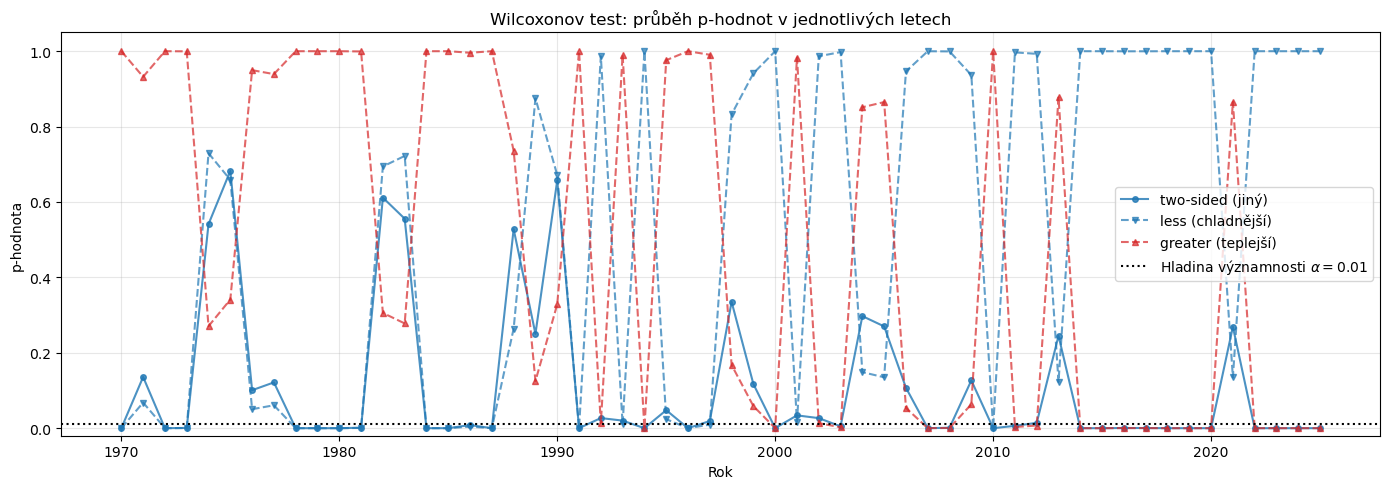

In [125]:
plot_test_results(tests_results[test_name][test_type], title=f"Wilcoxonov test: průběh p-hodnot v jednotlivých letech")

### 8. Analýza rozdílů použitých testů

In [126]:
def get_sig_years(test_name, test_type, alternative, alpha=0.01):
    p_vals = tests_results[test_name][test_type][alternative]
    return {year for year, p in p_vals.items() if p < alpha}

def comparison_table(alpha = 0.01):
    alternatives = {
        "two-sided": "Jiný (two-sided)",
        "less": "Chladnější (less)",
        "greater": "Teplejší (greater)",
    }
    rows = []
    for alt_key, alt_label in alternatives.items():
        ind_t = get_sig_years("t-test", "independent", alt_key, alpha)
        rel_t = get_sig_years("t-test", "paired", alt_key, alpha)
        wilc = get_sig_years("wilcoxon", "paired", alt_key, alpha)

        rows.append({
            "Hypotéza": alt_label,
            "Nepárový t-test (počet)": len(ind_t),
            "Párový t-test (počet)": len(rel_t),
            "Pouze párový t-test oproti nepárovému [počet]": len(rel_t - ind_t),
            "|" : "|",
            "Wilcoxon párový (počet)": len(wilc),
            "Párový t-test oproti Wilcoxon [roky[": sorted(rel_t - wilc),
            "Wilcoxon oprorti Párový t-test [roky]": sorted(wilc - rel_t),
        })
    return rows

df_comparison = pd.DataFrame(comparison_table())
display(df_comparison)

,Hypotéza,Nepárový t-test (počet),Párový t-test (počet),Pouze párový t-test oproti nepárovému [počet],|,Wilcoxon párový (počet),Párový t-test oproti Wilcoxon [roky[,Wilcoxon oprorti Párový t-test [roky]
0,Jiný (two-sided),9,30,21,|,31,[1971],"[2003, 2011]"
1,Chladnější (less),5,18,13,|,15,"[1971, 1993, 2001]",[]
2,Teplejší (greater),8,17,9,|,18,[],[2012]


...

Z analýzy vychází, že méně roků prochází nepárovým testem než párovým testem pro hladinu významnosti $\alpha = 0.01$.

Důvodem je robustnost párového testu vůči odchylkám. V nepárovém testu jsou odchylky hodnot napříč rokem obrovské. U párového testu nás zajímají odchylky pouze odpovídajících dnů a jsou tedy menší a "snadněji" se překonají.

Z analýzy vychází, že přibližně stejný počet roků prochází jak t-testem, tak neparametrickým testem pro hladinu významnosti $\alpha = 0.01$.

V tabulce výše jsou vidět konkrétní roky, ve kterých se paramterické testy liší oproti neparamterickému.

V teplotách se vyskytují extrémní mrazy (z histogramu odchylek jsou vidět odchylky až $-16^\circ\text{C}$), které nemají na kladné straně protějšek. T-test počítá s aritmetickým průměrem odchylek a tyto výrazné záporné odchylky strhly průměr směrem dolů.

Wilcoxonův test pracuje s pořadím. Výrazně mrazivý den nemá statisticky výraznější hodnotu než "obyčejný" chladný den.

Kvůli zápornému zešikmení leží medián (se kterým počítáme u neparamterického testu) o něco výše než jejich průměr.

T-test, který pracuje s průměrem tedy zachytil trochu více chladnějších let (o tři), zatímco Wilcoxonův neparametrický test zachytil více teplejších let (o jeden). 

Níže je tabulka srovnávající testy na hladině významnosti $\alpha=0.05$, jsou rozdíly mezi testy velice podobné jako pro hladinu významnosti $\alpha=0.01$.

In [127]:
df_comparison = pd.DataFrame(comparison_table(alpha=0.05))
display(df_comparison)

,Hypotéza,Nepárový t-test (počet),Párový t-test (počet),Pouze párový t-test oproti nepárovému [počet],|,Wilcoxon párový (počet),Párový t-test oproti Wilcoxon [roky[,Wilcoxon oprorti Párový t-test [roky]
0,Jiný (two-sided),18,38,20,|,38,"[1971, 1976]","[1995, 2012]"
1,Chladnější (less),11,20,9,|,18,"[1971, 1976]",[]
2,Teplejší (greater),11,19,8,|,20,[],[2012]


### 9. Analýza trendu

**Co vlastně řešíme?**
- Trend bude nějak kladně nebo záporně strmý $\to$
- $\to$ budeme řešit jestly sklon naší přímky je dostatečně strmý na to aby šlo o skutečně dlouhodobý odhad

- pod pojmem trend si tady představ Linearni regresi (nevim proč mi to neseplo hned)

**Pozor rok 2025 není úplný!**
- dojde k mírnému zkreslení výsledků
- (viz úkoly nad rámec zadání)

Obecná formulace hypotézy o trendu (slop):

* H0: trend je nulový
* H1: trend je nenulový.


Nalezení trendu, vykreslení a vyhodnocení p-hodnoty.

In [128]:
np.array(years)
df_annual_stats["mean"]

year
1970     8.103562
1971     8.653425
1972     8.140164
1973     8.706849
1974     9.529589
1975     9.330137
1976     8.899727
1977     9.044932
1978     8.000822
1979     8.189863
1980     7.747268
1981     8.578630
1982     9.106849
1983     9.363288
1984     8.240164
1985     7.828219
1986     8.545479
1987     7.640822
1988     9.177869
1989     9.553699
1990     9.414247
1991     8.352055
1992     9.634699
1993     8.791507
1994    10.209863
1995     8.967945
1996     7.317486
1997     8.818904
1998     9.600000
1999     9.533973
2000     9.996995
2001     8.901918
2002     9.719726
2003     9.827397
2004     9.142350
2005     9.030137
2006     9.507123
2007    10.173973
2008     9.847268
2009     9.465753
2010     8.190959
2011     9.760822
2012     9.537978
2013     9.086027
2014    10.653151
2015    10.875068
2016     9.884426
2017     9.836986
2018    10.978082
2019    10.769863
2020    10.475137
2021     9.171507
2022    10.669589
2023    11.060274
2024    11.368579
2025 

In [167]:
from scipy.stats import linregress

x_values = np.array(years)
y_values = df_annual_stats["mean"]

slope_lin_regress, intercept, r_value, p_value_lin_regress, std_err = linregress(x_values, y_values)



Sklon trendu (slope):      +0.0406 °C / rok (+0.406 °C / dekádu)
Úsek na ose y (intercept): -71.77 °C
Korelační koeficient (r):  0.7022 (R² = 0.4931)
Směrodatná chyba sklonu:   0.0056 °C / rok
p-hodnota:                 1.63e-09

Závěr (p-value: 1.63e-09 < alpha = 0.01): Zamítáme H0. 
Lineární trend je statisticky významně odlišný od nuly.


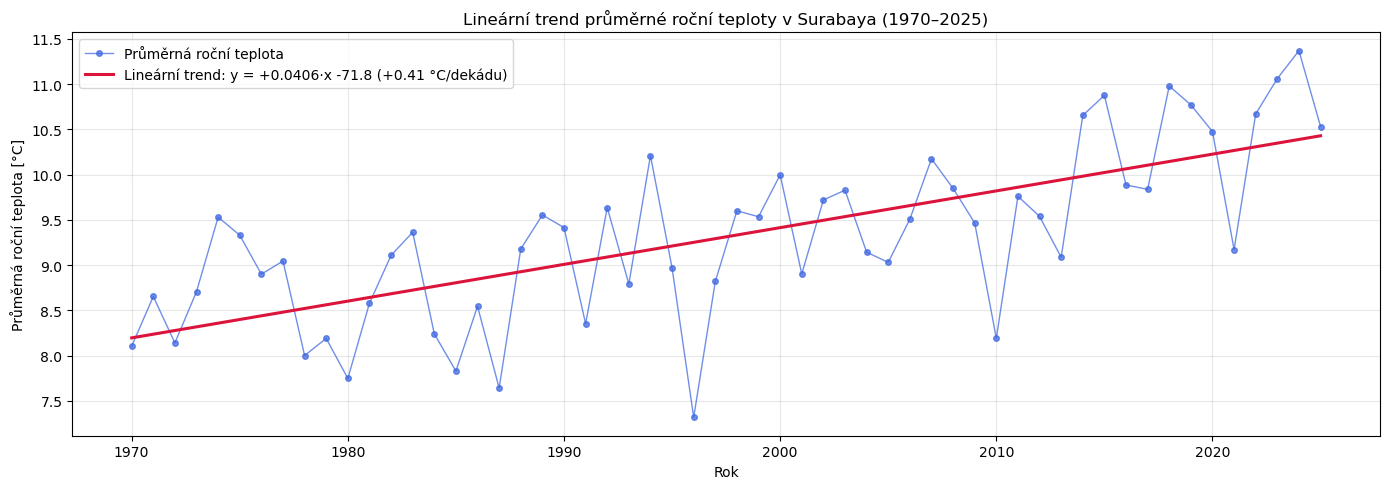

In [ ]:
def plot_lin_regress(x_values, y_values, slope_lin_regress, intercept, r_value, p_value_lin_regress, std_err):
    alpha = 0.01
    print(f"Sklon trendu (slope):      {slope_lin_regress:+.4f} °C / rok ({slope_lin_regress * 10:+.3f} °C / dekádu)")
    print(f"Úsek na ose y (intercept): {intercept:.2f} °C")
    print(f"Korelační koeficient (r):  {r_value:.4f} (R² = {r_value**2:.4f})")
    print(f"Směrodatná chyba sklonu:   {std_err:.4f} °C / rok")
    print(f"p-hodnota:                 {p_value_lin_regress:.2e}")

    if p_value_lin_regress < alpha:
        print(f"\nZávěr (p-value: {p_value_lin_regress:.2e} < alpha = {alpha}): Zamítáme H0. \nLineární trend je statisticky významně odlišný od nuly.")
    else:
        print(f"\nZávěr (p-value: {p_value_lin_regress} > alpha = {alpha}): Nezamítáme H0. \nNebyl prokázán statisticky významný trend.")

    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(
        x_values, y_values,
        marker="o", markersize=4, linewidth=1.0, alpha=0.75,
        color="royalblue", label="Průměrná roční teplota"
    )

    ax.plot(
        x_values, intercept + slope_lin_regress * x_values,
        color="crimson", linewidth=2.2,
        label=f"Lineární trend: y = {slope_lin_regress:+.4f}·x {intercept:+.1f} ({slope_lin_regress * 10:+.2f} °C/dekádu)"
    )

    ax.set_title(f"Lineární trend průměrné roční teploty v {location['name']} (1970-2025)")
    ax.set_xlabel("Rok")
    ax.set_ylabel("Průměrná roční teplota [°C]")
    ax.grid(True, alpha=0.3)
    ax.legend()

    fig.tight_layout()
    plt.show()

plot_lin_regress(x_values, y_values, slope_lin_regress, intercept, r_value, p_value_lin_regress, std_err)

Z grafu lineární regrese je patrný rosotoucí trend $0.0406^\circ\text{C}$ za rok. 

Jednotlivé roky vykazují variabilitu teplot (např. výrazně chladný rok 2010), ale dlouhodobý zvýšení teploty za sledované období rozptyl dat kolem regresní přímky převyšuje.
Směrodatná odchylka odhadu sklonu ($0.0056$) je oproti samotnému sklonu ($0.0406$) velmi malá a výsledná p-hodnota je výrazně nižší (o několik řádů!) než hladina významnosti $alpha = 0.01$.

Zamítáme proto nulovou hypotézu o nulovém trendu.

## Úkol 10 - Vypracování úkolu/ů nad rámec zadání
### Nalezené "problémy"
0. Neúplný rok 2025 zkresluje úkoly 4 a 9
- toto možná není nad rámec zadání a měl bych to ošetřit rovnou
- nezkresluje i jiné testy?
    - Párové testy nezkresulje, protože porovnáváme konkrétní dny 
1. Porovnávání roku se sebou samým (skoro)
- průměrný rok, který počítáme jako referenci pro testovaný rok, počítáme i testovaného roku
- nejvíce ovlivňuje přestupní roky
2. Předpoklad nezávislosti
- všechny použité testy předpokládají nezávislost pozorování
- to ovšem není u denních teplot zaručeno

## Řešení problému 0 - nekompletní rok 2025

In [131]:
df_complete_years = df[df["year"] < 2025].copy()
df_annual_stats_complete = df_annual_stats[df_annual_stats.index < 2025].copy()

res_complete = linregress(df_annual_stats_complete.index.to_numpy(), df_annual_stats_complete["mean"].to_numpy())

print(f"Průměrná teplota roku 2025 (pouze 346 dnů): {df_annual_stats.loc[2025, 'mean']:.2f} °C")
print(f"Trend 1970-2025: slope = {slope_lin_regress:+.4f} °C/rok (p = {p_value_lin_regress:.2e})")
print(f"Trend 1970-2024: slope = {res_complete.slope:+.4f} °C/rok (p = {res_complete.pvalue:.2e})")


Průměrná teplota roku 2025 (pouze 346 dnů): 10.53 °C
Trend 1970-2025: slope = +0.0406 °C/rok (p = 1.63e-09)
Trend 1970-2024: slope = +0.0404 °C/rok (p = 5.34e-09)


Pro t-test ořízneme průměrný rok na 346 dnů (pouze do 12.12.)

In [132]:
days_2025 = df_annual[2025]["date"].dt.day_of_year
actual_2025 = df_annual[2025]["temperature_mean"]
avg_same_days = df_average_year[df_average_year["day_of_year"].isin(days_2025)]["mean"]

p_2025_unfair_two_sided = tests_results["t-test"]["independent"]["two-sided"][2025]
p_2025_unfair_greater = tests_results["t-test"]["independent"]["greater"][2025]
p_2025_fair_two_sided = ttest_ind(actual_2025, avg_same_days, equal_var=False, alternative="two-sided").pvalue
p_2025_fair_greater = ttest_ind(actual_2025, avg_same_days, equal_var=False, alternative="greater").pvalue

print(f"\nNepárový t-test pro rok 2025 (greater):")
print(f"Původní (346 dnů vs. 366 dnů): p = {p_2025_unfair_greater:.5f}")
print(f"Opravený (346 dnů vs. 346 dnů): p = {p_2025_fair_greater:.5f}")

print(f"\nNepárový t-test pro rok 2025 (two_sided):")
print(f"Původní (346 dnů vs. 366 dnů): p = {p_2025_unfair_two_sided:.5f}")
print(f"Opravený (346 dnů vs. 346 dnů): p = {p_2025_fair_two_sided:.5f}")


Nepárový t-test pro rok 2025 (greater):
Původní (346 dnů vs. 366 dnů): p = 0.00986
Opravený (346 dnů vs. 346 dnů): p = 0.07793

Nepárový t-test pro rok 2025 (two_sided):
Původní (346 dnů vs. 366 dnů): p = 0.01971
Opravený (346 dnů vs. 346 dnů): p = 0.15586


Výsledky původního nepárového t-testu:
```
Hladina významnosti alpha = 0.01
Významně odlišné roky (two-sided) [9]: [1980, 1987, 1996, 2014, 2015, 2018, 2019, 2023, 2024]
Významně chladnější roky (less)   [5]: [1978, 1980, 1985, 1987, 1996]
Významně teplejší roky (greater)  [8]: [2014, 2015, 2018, 2019, 2022, 2023, 2024, 2025]
```

Po přepočtení p-hodnot pouze pro 346 dnů v roce nám vychází výrazně vyšší p-hodnota. Výsledek pro oboustranný test zůstane stejný (rok stále není výrazně odlišný).

Ale pro jednostranný test (greater) p-hodnota překročila hladinu významnosti $\alpha = 0.01$ a nezamítáme tedy $H_0$.

### Oprava problému 1 - testovaný rok součástí referenčního průměru

2026-11-18 - tady jsem "skončil" -> tady pokračuj

In [133]:
def get_leave_one_out_average_year(df_all, target_year):
    """
    Vrátí DataFrame se sloupci ['day_of_year', 'mean'] spočítaný
    ze všech let kromě target_year (prevence data leakage).
    """
    df_others = df_all[df_all["year"] != target_year]
    df_avg_loo = (
        df_others.groupby("day_of_year")["temperature_mean"]
        .mean()
        .reset_index()
    )
    return df_avg_loo

# Ukázka zapojení do existující smyčky (pro párový t-test i Wilcoxon):
loo_results = {
    "t-test": {"two-sided": {}, "less": {}, "greater": {}},
    "wilcoxon": {"two-sided": {}, "less": {}, "greater": {}},
}

for year, data in df_annual.items():
    actual_year_df = pd.DataFrame({
        "day_of_year": data["date"].dt.day_of_year,
        "temperature": data["temperature_mean"],
    })

    # Zde pouze nahradíme globální průměr za Leave-One-Out průměr
    avg_loo_df = get_leave_one_out_average_year(df, year)

    merged = pd.merge(actual_year_df, avg_loo_df, on="day_of_year", how="left")
    act = merged["temperature"]
    ref = merged["temperature_mean"]

    for alt in ("two-sided", "less", "greater"):
        loo_results["t-test"][alt][year] = ttest_rel(act, ref, alternative=alt).pvalue
        loo_results["wilcoxon"][alt][year] = wilcoxon(act, ref, alternative=alt).pvalue




Hladina významnosti alpha = 0.01
Významně odlišné roky (two-sided) [30]: [1970, 1971, 1972, 1973, 1978, 1979, 1980, 1981, 1984, 1985, 1986, 1987, 1991, 1994, 1996, 2000, 2007, 2008, 2010, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2022, 2023, 2024, 2025]
Významně chladnější roky (less)   [18]: [1970, 1971, 1972, 1973, 1978, 1979, 1980, 1981, 1984, 1985, 1986, 1987, 1991, 1993, 1996, 1997, 2001, 2010]
Významně teplejší roky (greater)  [17]: [1994, 2000, 2003, 2007, 2008, 2011, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2022, 2023, 2024, 2025]


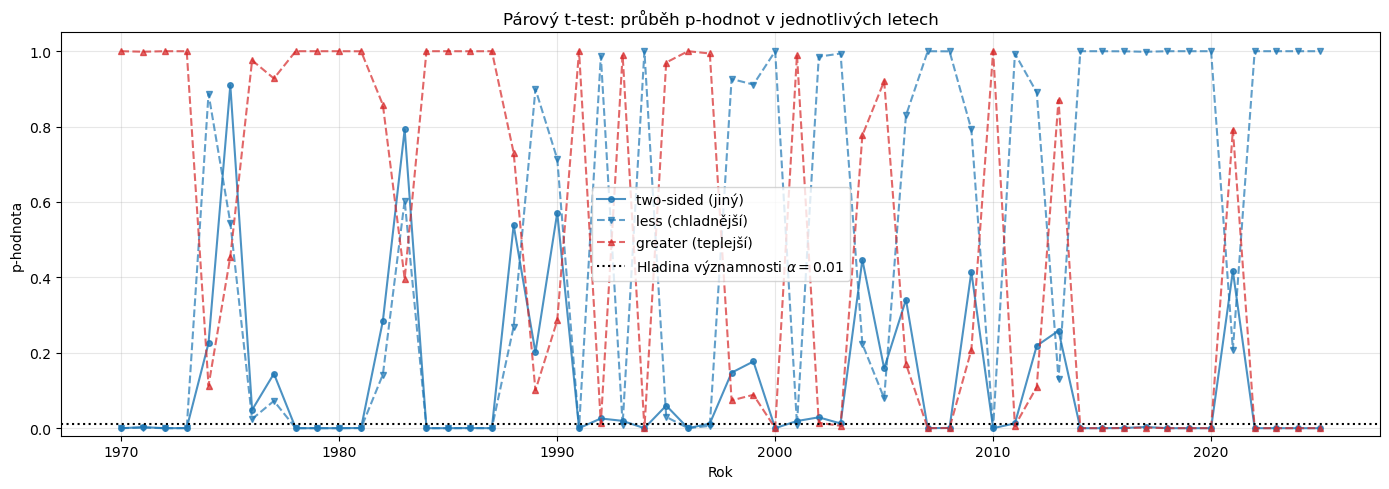

In [134]:
plot_test_results(loo_results["t-test"], title="Párový t-test: průběh p-hodnot v jednotlivých letech")

Hladina významnosti alpha = 0.01
Významně odlišné roky (two-sided) [31]: [1970, 1972, 1973, 1978, 1979, 1980, 1981, 1984, 1985, 1986, 1987, 1991, 1994, 1996, 2000, 2003, 2007, 2008, 2010, 2011, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2022, 2023, 2024, 2025]
Významně chladnější roky (less)   [15]: [1970, 1972, 1973, 1978, 1979, 1980, 1981, 1984, 1985, 1986, 1987, 1991, 1996, 1997, 2010]
Významně teplejší roky (greater)  [18]: [1994, 2000, 2003, 2007, 2008, 2011, 2012, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2022, 2023, 2024, 2025]


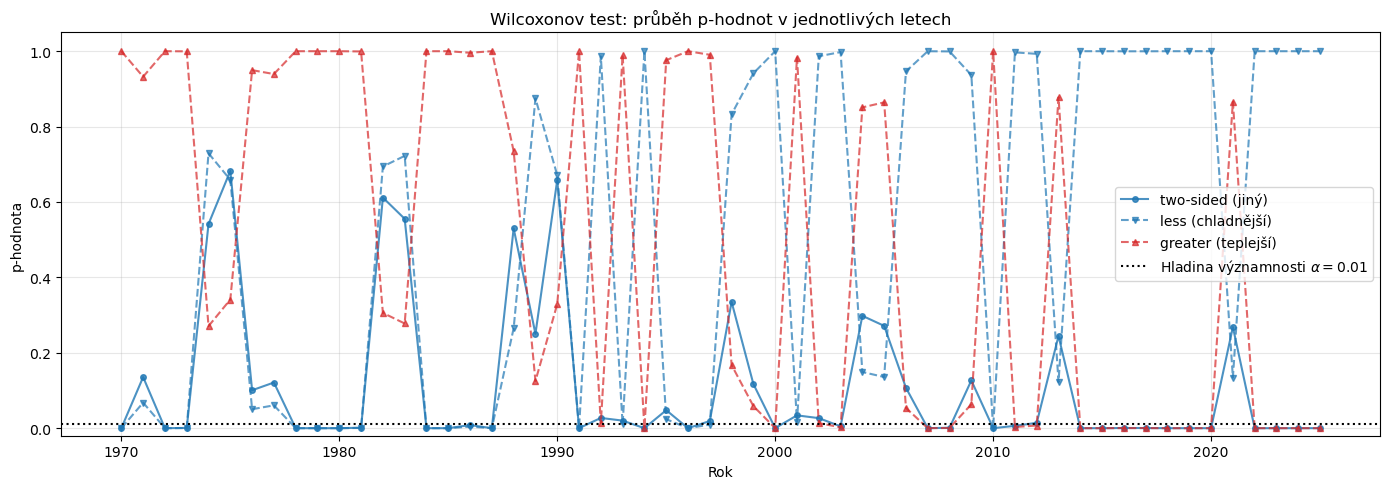

In [135]:
plot_test_results(loo_results["wilcoxon"], title="Wilcoxonov test: průběh p-hodnot v jednotlivých letech")

K žádnému rozdílu oproti předchozím výpočtům, kde se pracovalo s klasickým průměrem, nedošlo.

### Oprava problému 2 - autokorelace dat

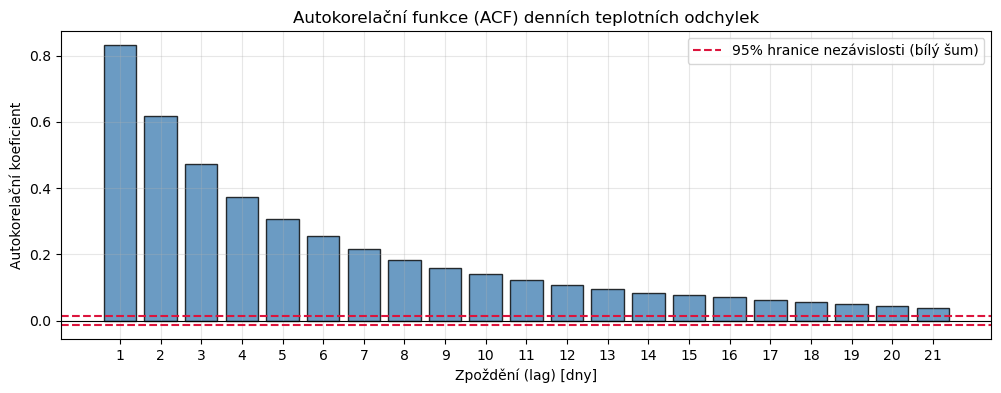

Autokorelace pro zpoždění 1 den:  r(1) = 0.831
Autokorelace pro zpoždění 7 dnů:  r(7) = 0.216


In [136]:
# 3A. Diagnostika: Výpočet a vykreslení autokorelace denních odchylek (lag 1 až 21 dnů)
max_lag = 21
lags = np.arange(1, max_lag + 1)
autocorrs = [deviation.autocorr(lag=k) for k in lags]

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(lags, autocorrs, color="steelblue", edgecolor="black", alpha=0.8)
ax.axhline(0, color="black", linewidth=0.8)

# Orientační 95% pásmo nevýznamnosti pro bílý šum (±1.96 / sqrt(N))
conf_bound = 1.96 / np.sqrt(len(deviation))
ax.axhline(conf_bound, color="crimson", linestyle="--", label="95% hranice nezávislosti (bílý šum)")
ax.axhline(-conf_bound, color="crimson", linestyle="--")

ax.set_title("Autokorelační funkce (ACF) denních teplotních odchylek")
ax.set_xlabel("Zpoždění (lag) [dny]")
ax.set_ylabel("Autokorelační koeficient")
ax.set_xticks(lags)
ax.grid(alpha=0.3)
ax.legend()
plt.show()

print(f"Autokorelace pro zpoždění 1 den:  r(1) = {autocorrs[0]:.3f}")
print(f"Autokorelace pro zpoždění 7 dnů:  r(7) = {autocorrs[6]:.3f}")

# 3B. Příprava dat pro nápravu: Agregace na měsíční průměry (12 pozorování za rok místo 365)
df["month"] = df["date"].dt.month
df_monthly = (
    df.groupby(["year", "month"])["temperature_mean"]
    .mean()
    .reset_index()
)

df_average_month = (
    df_monthly.groupby("month")["temperature_mean"]
    .mean()
    .rename("mean")
    .reset_index()
)

Místo toho abychom počítali s korelovanými daty dnů, budeme počítat s méně korelovanými daty měsíců. Snížíme tím ale počet pozorování z 365/366 na pouhých 12.

In [137]:
monthly_results = {
    "t-test": {"two-sided": {}, "less": {}, "greater": {}},
    "wilcoxon": {"two-sided": {}, "less": {}, "greater": {}},
}

for year, group in df_monthly.groupby("year"):
    # Leave-One-Out průměr pro měsíce (ze všech let kromě testovaného roku)
    avg_month_loo = (
        df_monthly[df_monthly["year"] != year]
        .groupby("month")["temperature_mean"]
        .mean()
        .reset_index()
        .rename(columns={"temperature_mean": "mean"})
    )

    merged_m = pd.merge(group, avg_month_loo, on="month", how="left")
    act_m = merged_m["temperature_mean"]
    ref_m = merged_m["mean"]

    for alt in ("two-sided", "less", "greater"):
        monthly_results["t-test"][alt][year] = ttest_rel(act_m, ref_m, alternative=alt).pvalue
        monthly_results["wilcoxon"][alt][year] = wilcoxon(act_m, ref_m, alternative=alt).pvalue

# Využijeme tvou existující funkci plot_test_results pro výpis a graf!

Hladina významnosti alpha = 0.01
Významně odlišné roky (two-sided) [8]: [1978, 1980, 1996, 2014, 2019, 2022, 2023, 2024]
Významně chladnější roky (less)   [6]: [1970, 1972, 1978, 1980, 1984, 1996]
Významně teplejší roky (greater)  [7]: [2014, 2015, 2019, 2020, 2022, 2023, 2024]


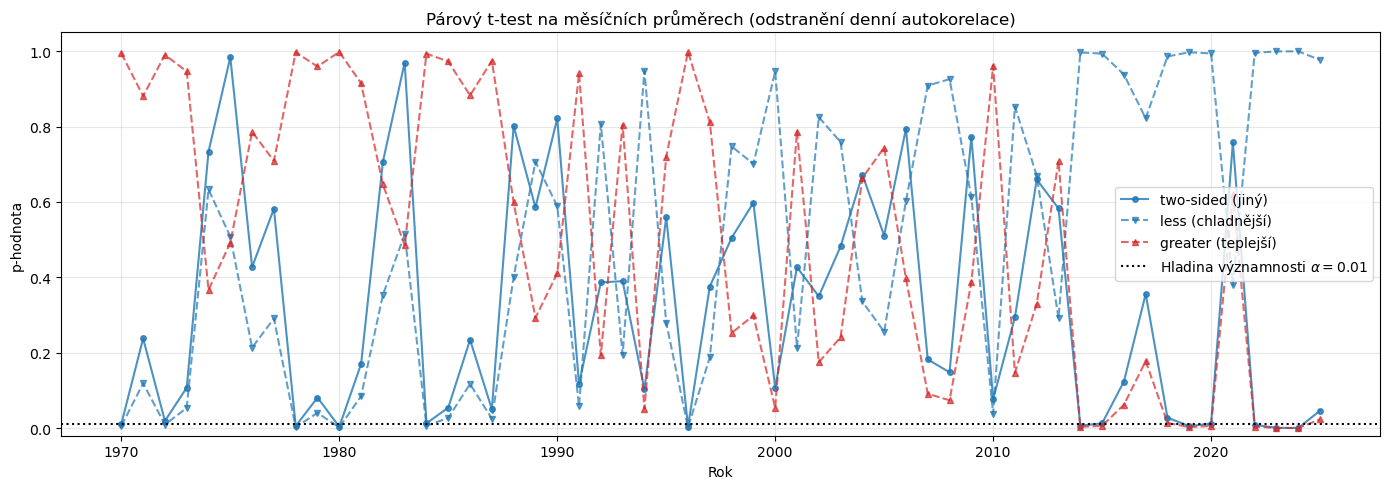

In [138]:
plot_test_results(monthly_results["t-test"], title="Párový t-test na měsíčních průměrech (odstranění denní autokorelace)")

Pro párový t-test se počet statisticky významných roků změnil z 30 na 8 pro obousměrnný test, počet chladnějších roků se změnil z 18 na 6 a počet teplejších roků se změnil z17 na 7.

Hladina významnosti alpha = 0.01
Významně odlišné roky (two-sided) [6]: [1978, 1996, 2014, 2020, 2023, 2024]
Významně chladnější roky (less)   [3]: [1978, 1980, 1996]
Významně teplejší roky (greater)  [6]: [2014, 2015, 2020, 2022, 2023, 2024]


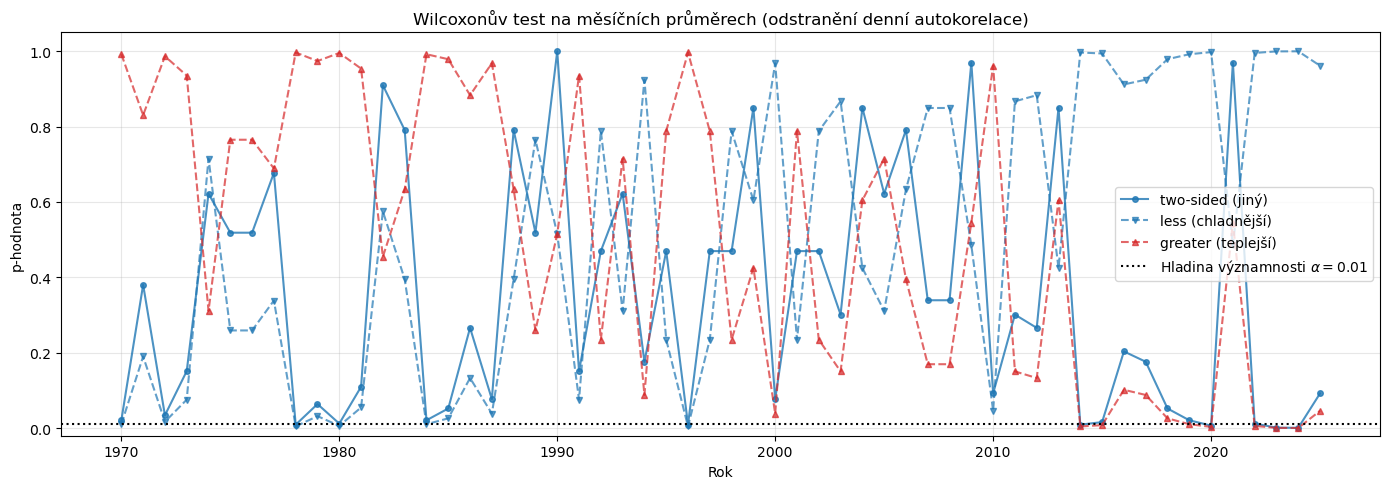

In [139]:
plot_test_results(monthly_results["wilcoxon"], title="Wilcoxonův test na měsíčních průměrech (odstranění denní autokorelace)")

Pro Wilcoxonův test se počet statisticky významných roků změnil z 31 na 6 pro obousměrnný test, počet chladnějších roků se změnil z 15 na 3 a počet teplejších roků se změnil z 18 na 6.

TODO - co navic -> smaž až to budeš mít:
1. Které dny nebo měsíce v roce se nejlépe hodí pro detekci oteplování?
~~2. Srovnání Plzně s jiným místem na planetě~~
3. Asymetrie oteplování: Denní minima (temperature_min) vs. maxima (temperature_max)
4. Testování hypotéz o rozptylu (Mění se jen průměrná teplota, nebo i extrémnost počasí?)

# Úkol 11. Srovnání Plzně a města "Sarabuya" v Indonésii
- pozn.: nevím jak se město Sarabuya skloňuje

In [152]:
# --------------------------------------------------
# Configuration
# --------------------------------------------------

location = {
    "name": "Surabaya",
    "continent": "Asia",
    "timezone": "Asia/Jakarta",
    "latitude": (-7, -14, -45),   # 7° 14' 45" S (jižní šířka -> záporné hodnoty)
    "longitude": (112, 44, 16),   # 112° 44' 16" E (východní délka)
}

for key in ("latitude", "longitude"):
    degrees, minutes, seconds = location[key]
    location[key] = degrees + minutes / 60 + seconds / 3600

start_date = "1970-01-01"
# end_date = "2025-12-31"
end_date = "2025-12-12" # zadani rika 12. prosince, ale tady bylo napsano 31. prosince
# Preklep, nebo kontrola toho ze jsem cetl zadani?
# nebo kontrola toho ze to byla hozeny cely do LLMka?
# who knows

# --------------------------------------------------
# Derived parameters
# --------------------------------------------------

# --------------------------------------------------
# Output
# --------------------------------------------------

print(f"Location: {location['name']}")
print(f"Continent: {location['continent']}")
print(f"Timezone: {location['timezone']}")
print(f"Latitude: {location['latitude']}")
print(f"Longitude: {location['longitude']}")
print(f"Start date: {start_date}")
print(f"End date: {end_date}")

Location: Surabaya
Continent: Asia
Timezone: Asia/Jakarta
Latitude: -7.245833333333334
Longitude: 112.73777777777778
Start date: 1970-01-01
End date: 2025-12-12


In [153]:
import datetime

date_start = datetime.date.fromisoformat(start_date)
date_end = datetime.date.fromisoformat(end_date)

n_days_expected = (date_end - date_start).days + 1

print(f"Start date: {date_start}")
print(f"End date: {date_end}")
print(f"Expected number of observations: {n_days_expected:,}")

Start date: 1970-01-01
End date: 2025-12-12
Expected number of observations: 20,435


In [ ]:
import requests
import pandas as pd
import json

# --------------------------------------------------
# Open-Meteo API
# --------------------------------------------------

url = "https://archive-api.open-meteo.com/v1/archive"

daily_variables = [
    "temperature_2m_mean",
    "temperature_2m_min",
    "temperature_2m_max",
]

params = {
    "latitude": location["latitude"],
    "longitude": location["longitude"],
    "start_date": start_date,
    "end_date": end_date,
    "daily": daily_variables,
    "timezone": location["timezone"],
    "models": "era5",
}

# --------------------------------------------------
# Download data
# --------------------------------------------------

# Pro prevenci příliš častého volání api jsem po prvním spuštění data uložil do souboru data.json
# with requests.Session() as session:
#     response = session.get(url, params=params, timeout=(10, 120))
#     response.raise_for_status()
#     result = response.json()

# json_str = json.dumps(result, indent=2)
# with open("data_Surabaya.json", "w") as f:
#     f.write(json_str)


with open("data_Surabaya.json") as f:
    result = json.load(f)



# --------------------------------------------------
# Extract data
# --------------------------------------------------

if "daily" not in result:
    raise ValueError("Daily data are missing from the API response.")

daily = result["daily"]

df = pd.DataFrame({
    "date": pd.to_datetime(daily["time"]),
    "temperature_mean": daily["temperature_2m_mean"],
    "temperature_min": daily["temperature_2m_min"],
    "temperature_max": daily["temperature_2m_max"],
})

# --------------------------------------------------
# Data validation
# --------------------------------------------------

print(f"Obtained observations: {len(df):,}")
print(f"Expected observations: {n_days_expected:,}")

if len(df) != n_days_expected:
    print("WARNING: Unexpected number of observations!")

if df["date"].duplicated().any():
    raise ValueError("Duplicate dates detected.")

if not df["date"].is_monotonic_increasing:
    raise ValueError("Dates are not in chronological order.")

missing = df.isna().sum()

if missing.any():
    print("\nMissing values:")
    print(missing[missing > 0])

# --------------------------------------------------
# API metadata
# --------------------------------------------------

print("\nTemperature units:")
print(result.get("daily_units", {}))

print(f"\nTimezone: {result.get('timezone')}")
print(f"Elevation: {result.get('elevation')} m")

df.head()

Obtained observations: 20,435
Expected observations: 20,435

Temperature units:
{'time': 'iso8601', 'temperature_2m_mean': '°C', 'temperature_2m_min': '°C', 'temperature_2m_max': '°C'}

Timezone: Asia/Jakarta
Elevation: 5.0 m


,date,temperature_mean,temperature_min,temperature_max
0,1970-01-01,27.8,24.7,31.1
1,1970-01-02,26.9,24.1,29.1
2,1970-01-03,27.4,24.6,30.2
3,1970-01-04,27.3,25.2,31.4
4,1970-01-05,27.0,24.6,30.8


In [166]:
df_surabaya = df.copy()
df_surabaya["year"] = df_surabaya["date"].dt.year
df_surabaya["day_of_year"] = df_surabaya["date"].dt.day_of_year

df_annual_surabaya = {
    year: group.drop(columns="year").reset_index(drop=True)
    for year, group in df_surabaya.groupby("year")
}

df_average_year_surabaya = (
    df_surabaya.groupby("day_of_year")["temperature_mean"]
    .agg(["mean", "std"])
    .reset_index()
)

df_average_year_surabaya

,day_of_year,mean,std
0,1,27.166071,0.839540
1,2,27.201786,0.909644
2,3,27.285714,0.884910
3,4,27.225000,0.906191
4,5,27.135714,0.848620
...,...,...,...
361,362,27.480000,0.969421
362,363,27.481818,0.922374
363,364,27.387273,0.905754
364,365,27.247273,0.885449


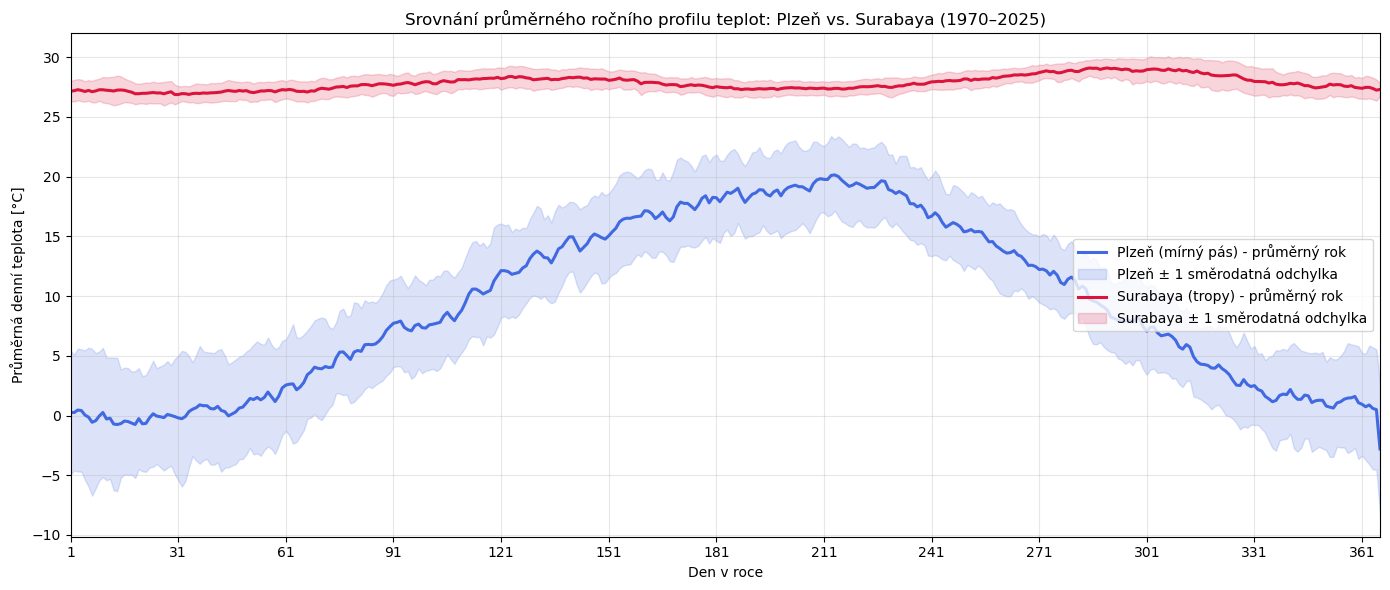

In [173]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 6))

# Plzeň – průměrný rok a pásmo ±1 std
ax.plot(
    df_average_year["day_of_year"],
    df_average_year["mean"],
    color="royalblue",
    linewidth=2.2,
    label="Plzeň (mírný pás) - průměrný rok",
)
ax.fill_between(
    df_average_year["day_of_year"],
    df_average_year["mean"] - df_average_year["std"],
    df_average_year["mean"] + df_average_year["std"],
    color="royalblue",
    alpha=0.18,
    label="Plzeň ± 1 směrodatná odchylka",
)

# Surabaya – průměrný rok a pásmo ±1 std
ax.plot(
    df_average_year_surabaya["day_of_year"],
    df_average_year_surabaya["mean"],
    color="crimson",
    linewidth=2.2,
    label="Surabaya (tropy) - průměrný rok",
)
ax.fill_between(
    df_average_year_surabaya["day_of_year"],
    df_average_year_surabaya["mean"] - df_average_year_surabaya["std"],
    df_average_year_surabaya["mean"] + df_average_year_surabaya["std"],
    color="crimson",
    alpha=0.18,
    label="Surabaya ± 1 směrodatná odchylka",
)

ax.set_title("Srovnání průměrného ročního profilu teplot: Plzeň vs. Surabaya (1970–2025)")
ax.set_xlabel("Den v roce")
ax.set_ylabel("Průměrná denní teplota [°C]")
ax.set_xlim(1, 366)
ax.set_xticks(range(1, 367, 30))
ax.grid(True, alpha=0.3)
ax.legend(loc="center right")

fig.tight_layout()
plt.show()

Z dat je vidět, že průměrná teplota je v průběhu roku podstatně vyšší.


Sklon trendu (slope):      +0.0245 °C / rok (+0.245 °C / dekádu)
Úsek na ose y (intercept): -21.17 °C
Korelační koeficient (r):  0.8733 (R² = 0.7627)
Směrodatná chyba sklonu:   0.0019 °C / rok
p-hodnota:                 3.48e-18

Závěr (p-value: 3.48e-18 < alpha = 0.01): Zamítáme H0. 
Lineární trend je statisticky významně odlišný od nuly.


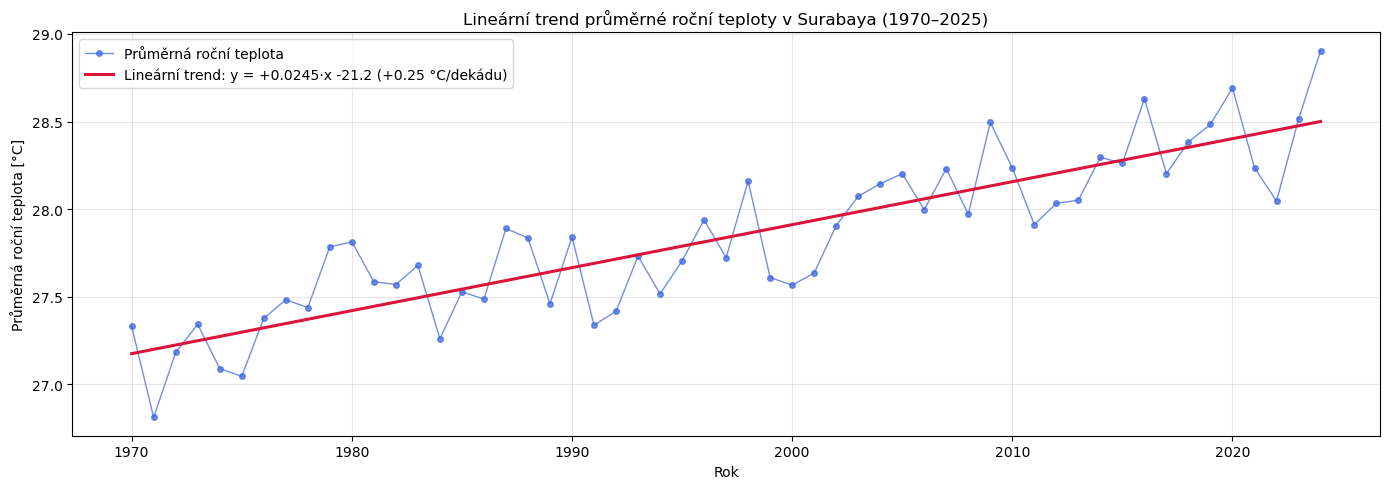

In [179]:
df_annual_stats_surabaya = pd.DataFrame({
    year: {
        "mean": data["temperature_mean"].mean(),
    }
    for year, data in df_annual_surabaya.items()
    if len(data) >= 365  # automaticky vyřadí neúplný rok 2025 (346 dnů)
}).T
df_annual_stats_surabaya.index.name = "year"

x_values = df_annual_stats_surabaya.index.to_numpy()
y_values = df_annual_stats_surabaya["mean"]

slope_lin_regress, intercept, r_value, p_value_lin_regress, std_err = linregress(x_values, y_values)

plot_lin_regress(x_values, y_values, slope_lin_regress, intercept, r_value, p_value_lin_regress, std_err)


Graf vypadá velice podobně, ale má jiné měřítko, které zkresluje jak moc průměrná teplota stoupá.

In [180]:
def plot_multiple_lin_regress(series_dict, title="Srovnání lineárních trendů průměrné roční teploty"):
    fig, ax = plt.subplots(figsize=(14, 6))
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    for idx, (label, (x_vals, y_vals)) in enumerate(series_dict.items()):
        x_arr = np.asarray(x_vals)
        y_arr = np.asarray(y_vals)
        color = colors[idx % len(colors)]

        res = linregress(x_arr, y_arr)

        # Naměřené roční průměry
        ax.plot(
            x_arr,
            y_arr,
            marker="o",
            markersize=4,
            linewidth=1.0,
            alpha=0.55,
            color=color,
            label=f"{label} – data",
        )

        # Proložená regresní přímka
        ax.plot(
            x_arr,
            res.intercept + res.slope * x_arr,
            linestyle="--",
            linewidth=2.3,
            color=color,
            label=f"{label} – trend ({res.slope * 10:+.2f} °C/dekádu, R²={res.rvalue**2:.2f})",
        )

    ax.set_title(title)
    ax.set_xlabel("Rok")
    ax.set_ylabel("Průměrná roční teplota [°C]")
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=2)

    fig.tight_layout()
    plt.show()

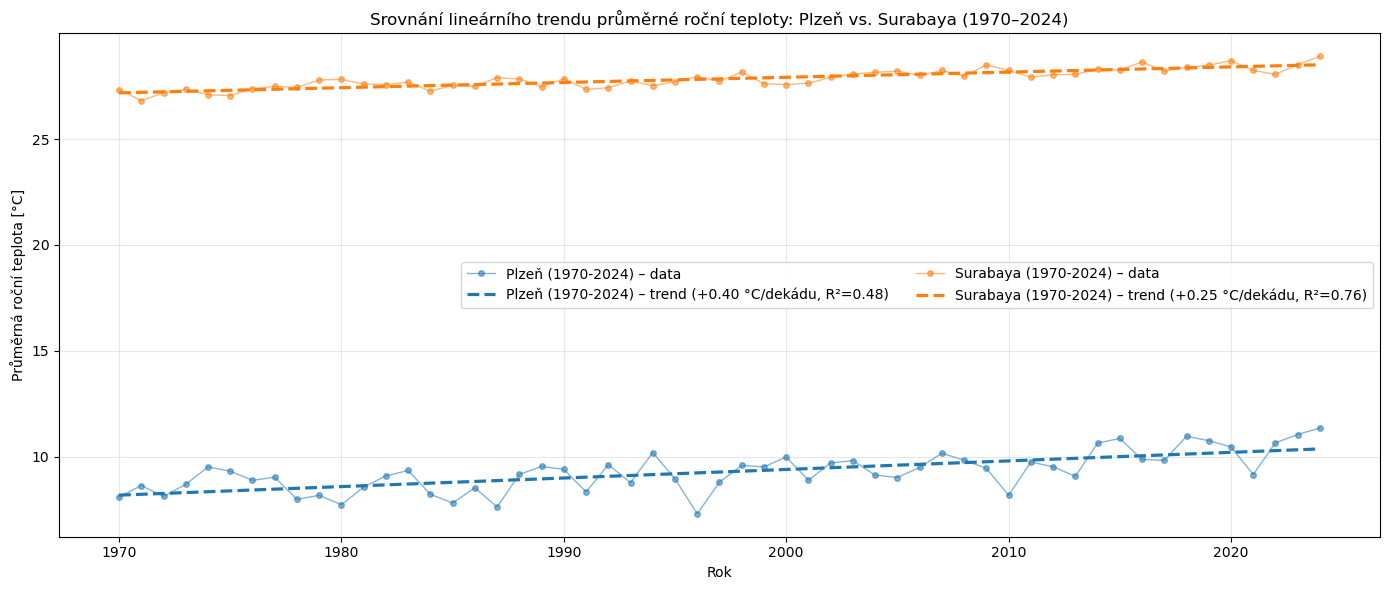

In [181]:
plot_multiple_lin_regress(
    {
        "Plzeň (1970-2024)": (
            df_annual_stats_complete.index,
            df_annual_stats_complete["mean"],
        ),
        "Surabaya (1970-2024)": (
            df_annual_stats_surabaya.loc[:2024].index,
            df_annual_stats_surabaya.loc[:2024, "mean"],
        ),
    },
    title="Srovnání lineárního trendu průměrné roční teploty: Plzeň vs. Surabaya (1970–2024)",
)

V Sarabuye je stoupne teplota o $0.0245^\circ\text{C}$, což je méně než v Plzni, ale je stále k vidění roustoucí trend teplot.

V další buňce jsou zopakované úkoly 4, 5 a 7 (nepárový a párový t-test a Wilcoxonův neparamterický test).

In [ ]:
tests_results_Surabaya = {}

test_name = "t-test"
test_type = "independent"

tests_results_Surabaya[test_name] = {
        test_type: {
            "two-sided": {},
            "less": {},
            "greater": {},
        },
}

average_year = df_average_year_surabaya["mean"]

for year, data in df_annual_surabaya.items():

    actual_year = data["temperature_mean"] # vsechny data v roce

    p_value_two_sided = ttest_ind(actual_year,
                                   average_year,
                                   equal_var=False,
                                   alternative="two-sided").pvalue
    p_value_less = ttest_ind(actual_year,
                             average_year,
                             equal_var=False,
                             alternative="less").pvalue
    p_value_greater = ttest_ind(actual_year,
                                 average_year,
                                 equal_var=False,
                                 alternative="greater").pvalue  

    tests_results_Surabaya[test_name][test_type]["two-sided"][year] = p_value_two_sided
    tests_results_Surabaya[test_name][test_type]["less"][year] = p_value_less
    tests_results_Surabaya[test_name][test_type]["greater"][year] = p_value_greater



test_name = "t-test"
test_type = "paired"

tests_results_Surabaya[test_name][test_type] = {
            "two-sided": {},
            "less": {},
            "greater": {},
}

tests_results_Surabaya["wilcoxon"] = {
        test_type: {
            "two-sided": {},
            "less": {},
            "greater": {},
        },
}



average_year_with_days = df_average_year_surabaya[["mean","day_of_year"]]
print(len(average_year_with_days))
# prumerny rok obsahuje data i z 29. unora, coz je pouze pro prestupni roky

for year, data in df_annual_surabaya.items():
    # Musim mergenout podle datumu!
    actual_year_df = pd.DataFrame({
        "day_of_year": data["date"].dt.day_of_year,
        "temperature": data["temperature_mean"]
    })

    # data nejdrive mergnu, abych zajistil ze se v kazdem roce porovnavaji spravne dny
    merged = pd.merge(
        actual_year_df,
        average_year_with_days,
        on="day_of_year",
        how="left",
    )

    actual_year_data = merged["temperature"]
    average_year_data = merged["mean"]


    p_value_two_sided = ttest_rel(actual_year_data, average_year_data, alternative="two-sided").pvalue
    p_value_less = ttest_rel(actual_year_data, average_year_data, alternative="less").pvalue
    p_value_greater = ttest_rel(actual_year_data, average_year_data, alternative="greater").pvalue

    tests_results_Surabaya[test_name][test_type]["two-sided"][year] = p_value_two_sided
    tests_results_Surabaya[test_name][test_type]["less"][year] = p_value_less
    tests_results_Surabaya[test_name][test_type]["greater"][year] = p_value_greater

    p_value_two_sided_wilcoxon = wilcoxon(actual_year_data, average_year_data, alternative="two-sided").pvalue
    p_value_less_wilcoxon = wilcoxon(actual_year_data, average_year_data, alternative="less").pvalue
    p_value_greater_wilcoxon = wilcoxon(actual_year_data, average_year_data, alternative="greater").pvalue

    tests_results_Surabaya["wilcoxon"][test_type]["two-sided"][year] = p_value_two_sided_wilcoxon
    tests_results_Surabaya["wilcoxon"][test_type]["less"][year] = p_value_less_wilcoxon
    tests_results_Surabaya["wilcoxon"][test_type]["greater"][year] = p_value_greater_wilcoxon



366


Hladina významnosti alpha = 0.01
Významně odlišné roky (two-sided) [43]: [1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1981, 1982, 1983, 1984, 1985, 1986, 1989, 1991, 1992, 1994, 1998, 1999, 2000, 2001, 2003, 2004, 2005, 2007, 2009, 2010, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Významně chladnější roky (less)   [23]: [1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1981, 1982, 1983, 1984, 1985, 1986, 1989, 1991, 1992, 1994, 1995, 1999, 2000, 2001]
Významně teplejší roky (greater)  [22]: [1998, 2003, 2004, 2005, 2006, 2007, 2009, 2010, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


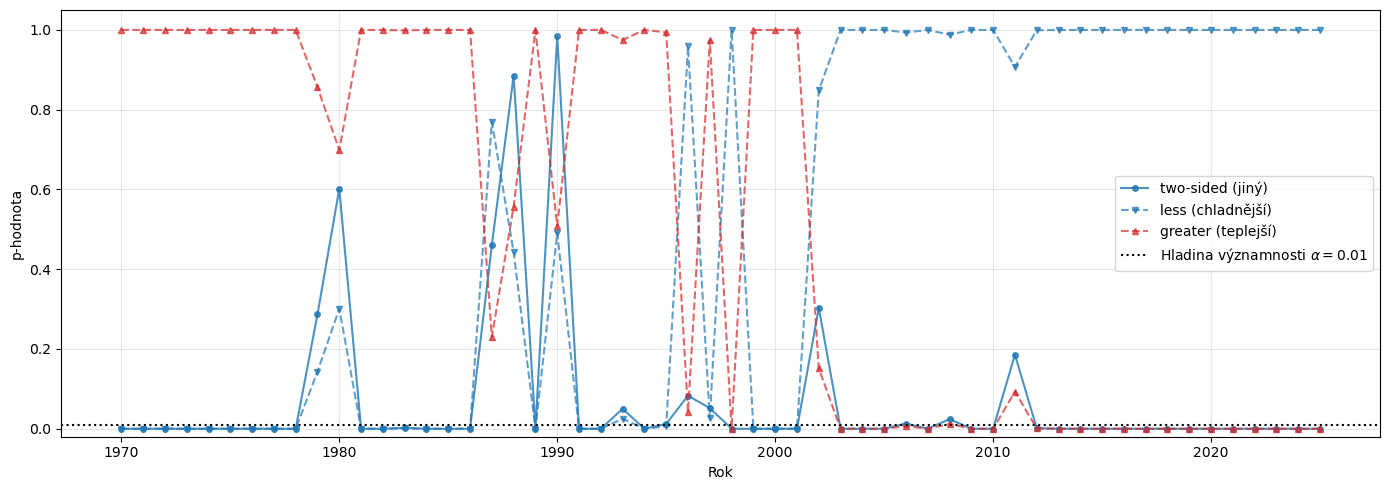

Hladina významnosti alpha = 0.01
Významně odlišné roky (two-sided) [49]: [1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1981, 1982, 1983, 1984, 1985, 1986, 1989, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Významně chladnější roky (less)   [25]: [1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1981, 1982, 1983, 1984, 1985, 1986, 1989, 1991, 1992, 1993, 1994, 1995, 1997, 1999, 2000, 2001]
Významně teplejší roky (greater)  [24]: [1996, 1998, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


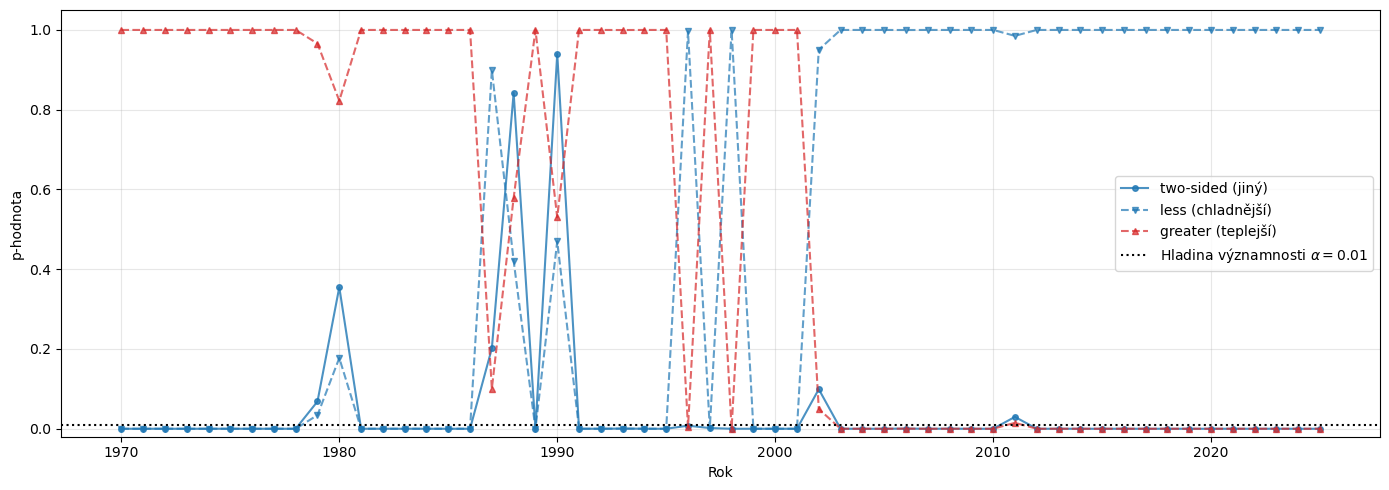

Hladina významnosti alpha = 0.01
Významně odlišné roky (two-sided) [48]: [1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1981, 1982, 1983, 1984, 1985, 1986, 1989, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2003, 2004, 2005, 2007, 2008, 2009, 2010, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Významně chladnější roky (less)   [25]: [1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1981, 1982, 1983, 1984, 1985, 1986, 1989, 1991, 1992, 1993, 1994, 1995, 1997, 1999, 2000, 2001]
Významně teplejší roky (greater)  [24]: [1996, 1998, 2003, 2004, 2005, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


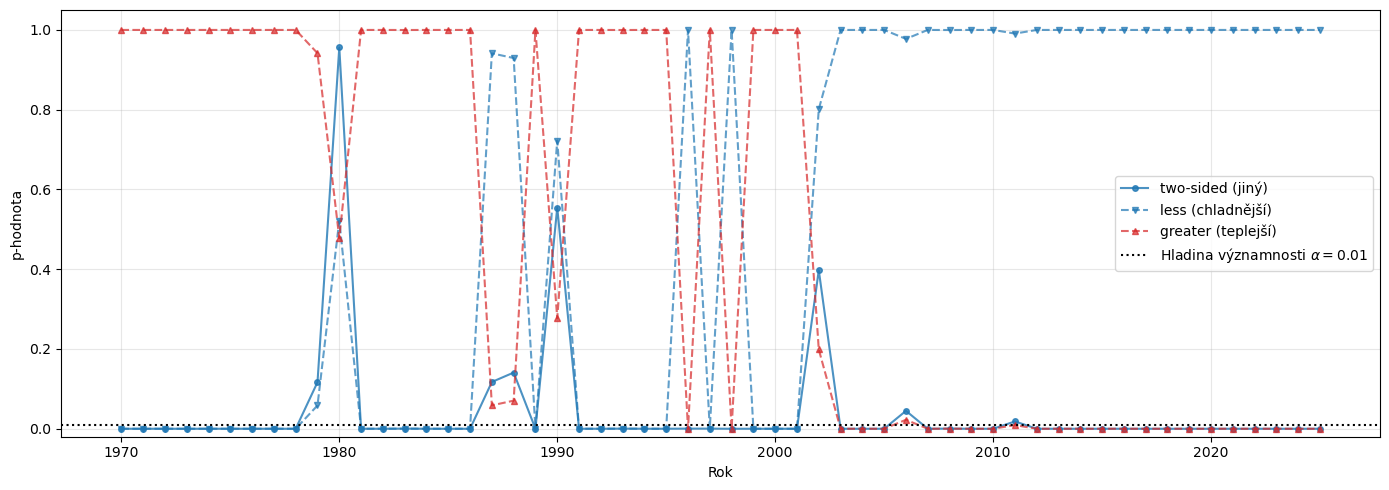

In [163]:

plot_test_results(tests_results_Surabaya["t-test"]["independent"], title=f"")
plot_test_results(tests_results_Surabaya["t-test"]["paired"], title=f"")
plot_test_results(tests_results_Surabaya["wilcoxon"]["paired"], title=f"")


Je k vidění, že nepárový test "netrpí" tolik na velké vnitro-roční rozptyly teplot a rozdíl je tedy mezi čtyřiceti třemi a čtyřiceti devíti lety (zatímco u Plzně to byl rozdíl mezi devíti a třiceti lety).

Celkově je statisticky odchýlených vždy alespoň čtyřicet tři let u všech oboustranných testů a dvacet u jednostranných testů.
Důvodem je menší rozptyl hodnot. Protože denní teploty kolísají kolem průměrných hodnot minimálně. 

To způsobuje, že i relativně malý dlouhodobý posun stačí k překročení hladiny významnosti.

In [ ]:
def compare_locations(results_plzen, results_surabaya, alpha=0.01):
    tests = [
        ("Nepárový Welchův t-test", "t-test", "independent"),
        ("Párový t-test", "t-test", "paired"),
        ("Wilcoxonův párový test", "wilcoxon", "paired"),
    ]
    alternatives = {
        "two-sided": "Jiný (two-sided)",
        "less": "Chladnější (less)",
        "greater": "Teplejší (greater)",
    }

    rows = []
    for test_label, t_name, t_type in tests:
        for alt_key, alt_label in alternatives.items():
            p_plzen = results_plzen[t_name][t_type][alt_key]
            p_sur = results_surabaya[t_name][t_type][alt_key]

            sig_plzen = {y for y, p in p_plzen.items() if p < alpha}
            sig_sur = {y for y, p in p_sur.items() if p < alpha}
            n_years = len(p_plzen)

            rows.append({
                "Test": test_label,
                "Hypotéza": alt_label,
                "Plzeň [počet]": len(sig_plzen),
                "Surabaya [počet]": len(sig_sur),
                "Plzeň [%]": round(100 * len(sig_plzen) / n_years, 1),
                "Surabaya [%]": round(100 * len(sig_sur) / n_years, 1),
                "Společné roky [počet]": len(sig_plzen & sig_sur),
                "Pouze Surabaya [počet]": len(sig_sur - sig_plzen),
            })

    return pd.DataFrame(rows)

df_loc_comparison = compare_locations(tests_results, tests_results_Surabaya, alpha=0.01)
display(df_loc_comparison)

,Test,Hypotéza,Plzeň [počet],Surabaya [počet],Plzeň [%],Surabaya [%],Společné roky [počet],Pouze Surabaya [počet]
0,Nepárový Welchův t-test,Jiný (two-sided),9,43,16.1,76.8,6,37
1,Nepárový Welchův t-test,Chladnější (less),5,23,8.9,41.1,2,21
2,Nepárový Welchův t-test,Teplejší (greater),8,22,14.3,39.3,8,14
3,Párový t-test,Jiný (two-sided),30,49,53.6,87.5,27,22
4,Párový t-test,Chladnější (less),18,25,32.1,44.6,13,12
5,Párový t-test,Teplejší (greater),17,24,30.4,42.9,14,10
6,Wilcoxonův párový test,Jiný (two-sided),31,48,55.4,85.7,27,21
7,Wilcoxonův párový test,Chladnější (less),15,25,26.8,44.6,10,15
8,Wilcoxonův párový test,Teplejší (greater),18,24,32.1,42.9,16,8


Z tabulky je vidět shoda u teplejších let. Jak u Wilcoxonového testu, tak u t-testu je vidět že velký počet let jsou společné jak pro Surabayu tak pro Plzeň. Pro Wilcoxonův test je to společných 16 z 18 pro Plzeň/z 24 pro Surabayu.  

# Úkol 12. Zkoumání extrémnosti počasí (testování hypotéz o rozptylu)
- cílem je zjistit zda se v Plzni v posleních letech mění pouze průměrná teplota bebo jestli se počasí stává extrémnějším (tedy jestli se zvyšuje rozptyl)
- TODO Co pouzivame za test + nejakej dalsi komentar

In [182]:
from scipy.stats import levene

def analyze_weather_extremes(
    df_location,
    location_name,
    early_period=(1970, 1989),
    recent_period=(2005, 2024),
    alpha=0.01,
):
    """
    Porovná rozptyl (extrémnost) denních teplotních odchylek mezi dvěma obdobími
    pomocí robustního Leveneova testu (center='median') a vykreslí histogramy.
    """
    data = df_location.copy()
    if "year" not in data.columns:
        data["year"] = data["date"].dt.year
    if "day_of_year" not in data.columns:
        data["day_of_year"] = data["date"].dt.day_of_year

    # 1. Výpočet denních odchylek od průměrného dne v roce (pouze kompletní roky < 2025)
    data = data[data["year"] < 2025].copy()
    avg_day = (
        data.groupby("day_of_year")["temperature_mean"]
        .mean()
        .rename("avg_temp")
        .reset_index()
    )
    data = pd.merge(data, avg_day, on="day_of_year", how="left")
    data["deviation"] = data["temperature_mean"] - data["avg_temp"]

    # 2. Výběr dvou dvacetiletých období
    dev_early = data[data["year"].between(*early_period)]["deviation"]
    dev_recent = data[data["year"].between(*recent_period)]["deviation"]

    # 3. Výpis popisných statistik
    print(f"=== {location_name}: Analýza rozptylu denních teplotních odchylek ===")
    print(
        f"Období {early_period[0]}–{early_period[1]} (n = {len(dev_early)}): "
        f"mean = {dev_early.mean():+.2f} °C, std = {dev_early.std():.3f} °C, var = {dev_early.var():.3f} °C²"
    )
    print(
        f"Období {recent_period[0]}–{recent_period[1]} (n = {len(dev_recent)}): "
        f"mean = {dev_recent.mean():+.2f} °C, std = {dev_recent.std():.3f} °C, var = {dev_recent.var():.3f} °C²"
    )

    # 4. Leveneův test rovnosti rozptylů
    stat_levene, p_levene = levene(dev_early, dev_recent, center="median")
    print(f"Leveneův test: statistika W = {stat_levene:.4f}, p-hodnota = {p_levene:.4e}")

    if p_levene < alpha:
        print(f"Závěr (alpha = {alpha}): Zamítáme H0. Rozptyl (extrémnost) denních teplot se statisticky významně změnil.\n")
    else:
        print(f"Závěr (alpha = {alpha}): Nezamítáme H0. Nebyla prokázána statisticky významná změna rozptylu teplot.\n")

    # 5. Vizualizace překrytých histogramů s dynamickým rozsahem osy x
    x_min = min(dev_early.min(), dev_recent.min()) - 0.5
    x_max = max(dev_early.max(), dev_recent.max()) + 0.5
    bins = np.linspace(x_min, x_max, 50)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.hist(
        dev_early,
        bins=bins,
        density=True,
        alpha=0.5,
        color="royalblue",
        label=f"{early_period[0]}–{early_period[1]} (std = {dev_early.std():.2f} °C)",
    )
    ax.hist(
        dev_recent,
        bins=bins,
        density=True,
        alpha=0.5,
        color="crimson",
        label=f"{recent_period[0]}–{recent_period[1]} (std = {dev_recent.std():.2f} °C)",
    )

    ax.axvline(dev_early.mean(), color="royalblue", linestyle="--", linewidth=1.8)
    ax.axvline(dev_recent.mean(), color="crimson", linestyle="--", linewidth=1.8)

    ax.set_title(f"{location_name}: Porovnání rozdělení denních teplotních odchylek ({early_period[0]}–{early_period[1]} vs. {recent_period[0]}–{recent_period[1]})")
    ax.set_xlabel("Odchylka od průměrného dne v roce [°C]")
    ax.set_ylabel("Hustota pravděpodobnosti")
    ax.grid(True, alpha=0.3)
    ax.legend()

    fig.tight_layout()
    plt.show()

    return {
        "location": location_name,
        "std_early": dev_early.std(),
        "std_recent": dev_recent.std(),
        "W": stat_levene,
        "p_value": p_levene,
    }

=== Plzeň: Analýza rozptylu denních teplotních odchylek ===
Období 1970–1989 (n = 7305): mean = -0.39 °C, std = 0.729 °C, var = 0.532 °C²
Období 2005–2024 (n = 7305): mean = +0.45 °C, std = 0.774 °C, var = 0.600 °C²
Leveneův test: statistika W = 18.4491, p-hodnota = 1.7563e-05
Závěr (alpha = 0.01): Zamítáme H0. Rozptyl (extrémnost) denních teplot se statisticky významně změnil.



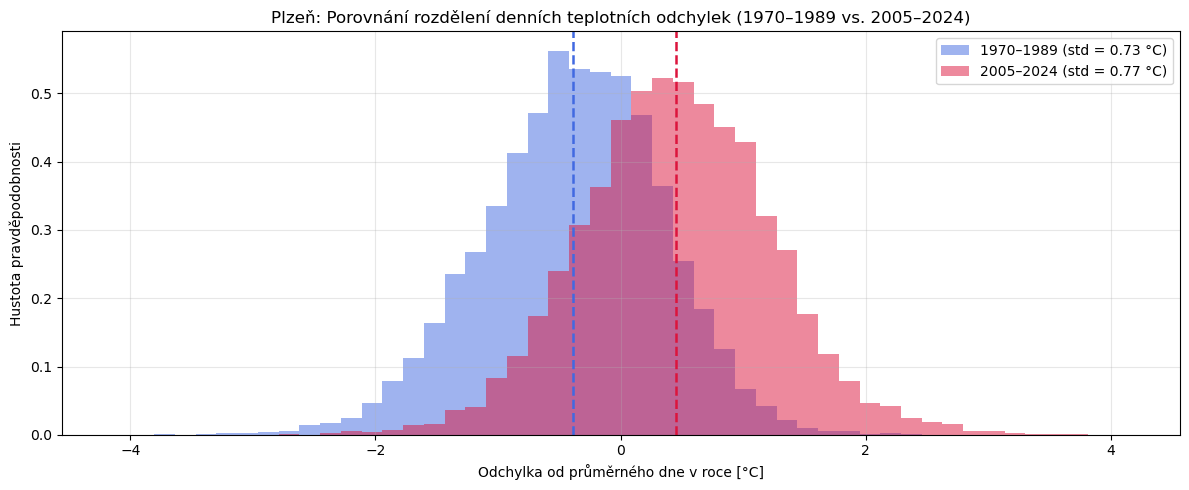

=== Surabaya: Analýza rozptylu denních teplotních odchylek ===
Období 1970–1989 (n = 7305): mean = -0.39 °C, std = 0.729 °C, var = 0.532 °C²
Období 2005–2024 (n = 7305): mean = +0.45 °C, std = 0.774 °C, var = 0.600 °C²
Leveneův test: statistika W = 18.4491, p-hodnota = 1.7563e-05
Závěr (alpha = 0.01): Zamítáme H0. Rozptyl (extrémnost) denních teplot se statisticky významně změnil.



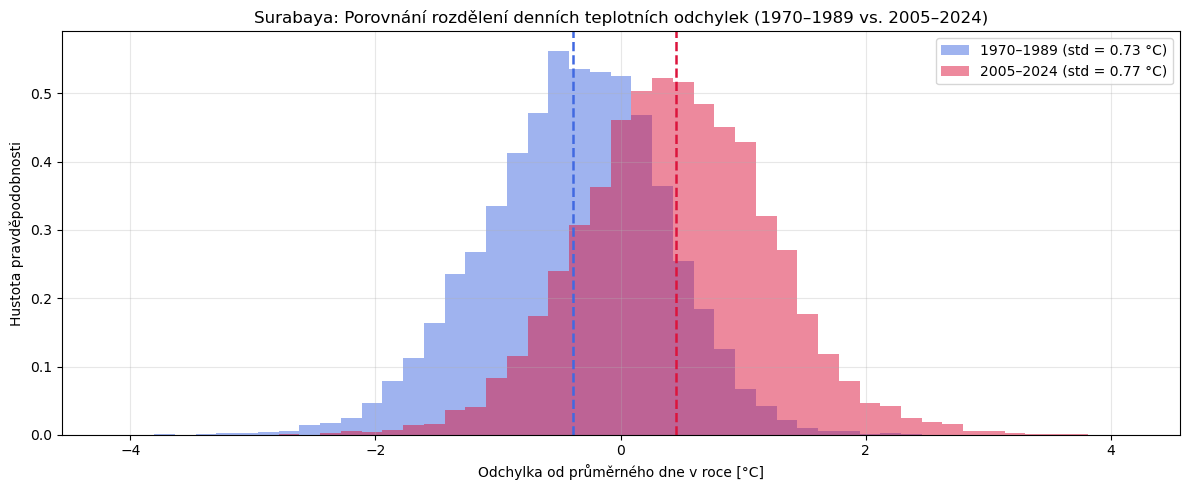

In [183]:
res_extremes_plzen = analyze_weather_extremes(df, "Plzeň")
res_extremes_surabaya = analyze_weather_extremes(df_surabaya, "Surabaya")

## Závěr

...